In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
import os
print(os.listdir("data"))

['salesforcourse-4fe2kehu.csv', 'salesforcourse-4fe2kehu.xlsx']


In [4]:
df = pd.read_csv("data/salesforcourse-4fe2kehu.csv")
print(df.shape)
df.head()

(34867, 16)


,index,Date,Year,Month,Customer Age,Customer Gender,Country,State,Product Category,Sub Category,Quantity,Unit Cost,Unit Price,Cost,Revenue,Column1
0,0,2/19/2016,2016.0,February,29.0,F,United States,Washington,Accessories,Tires and Tubes,1.0,80.00,109.000000,80.0,109.0,NaN
1,1,2/20/2016,2016.0,February,29.0,F,United States,Washington,Clothing,Gloves,2.0,24.50,28.500000,49.0,57.0,NaN
2,2,2/27/2016,2016.0,February,29.0,F,United States,Washington,Accessories,Tires and Tubes,3.0,3.67,5.000000,11.0,15.0,NaN
3,3,3/12/2016,2016.0,March,29.0,F,United States,Washington,Accessories,Tires and Tubes,2.0,87.50,116.500000,175.0,233.0,NaN
4,4,3/12/2016,2016.0,March,29.0,F,United States,Washington,Accessories,Tires and Tubes,3.0,35.00,41.666667,105.0,125.0,NaN


In [5]:
df.info()
print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 34867 entries, 0 to 34866
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   index             34867 non-null  int64  
 1   Date              34866 non-null  str    
 2   Year              34866 non-null  float64
 3   Month             34866 non-null  str    
 4   Customer Age      34866 non-null  float64
 5   Customer Gender   34866 non-null  str    
 6   Country           34866 non-null  str    
 7   State             34866 non-null  str    
 8   Product Category  34866 non-null  str    
 9   Sub Category      34866 non-null  str    
 10  Quantity          34866 non-null  float64
 11  Unit Cost         34866 non-null  float64
 12  Unit Price        34866 non-null  float64
 13  Cost              34866 non-null  float64
 14  Revenue           34867 non-null  float64
 15  Column1           2574 non-null   float64
dtypes: float64(8), int64(1), str(7)
memory usage: 6.2 M

In [6]:
print(list(df.columns))
df.sample(5, random_state=1)

['index', 'Date', 'Year', 'Month', 'Customer Age', 'Customer Gender', 'Country', 'State', 'Product Category', 'Sub Category', 'Quantity', 'Unit Cost', 'Unit Price', 'Cost', 'Revenue', 'Column1']


,index,Date,Year,Month,Customer Age,Customer Gender,Country,State,Product Category,Sub Category,Quantity,Unit Cost,Unit Price,Cost,Revenue,Column1
1541,1541,1/4/2016,2016.0,January,35.0,F,United States,California,Accessories,Tires and Tubes,3.0,9.00,11.000000,27.0,33.0,367.0
32811,32811,7/24/2015,2015.0,July,35.0,M,United States,California,Bikes,Touring Bikes,3.0,794.67,730.666667,2384.0,2192.0,NaN
16823,16823,11/9/2015,2015.0,November,43.0,M,United States,Washington,Accessories,Helmets,3.0,326.67,359.000000,980.0,1077.0,NaN
34079,34079,9/25/2015,2015.0,September,57.0,M,United States,Oregon,Clothing,Socks,3.0,39.00,43.000000,117.0,129.0,NaN
32449,32449,4/7/2016,2016.0,April,58.0,F,United States,California,Accessories,Tires and Tubes,3.0,83.33,113.666667,250.0,341.0,NaN


## 1. Dataset Overview and Data Cleaning

**Dataset:** Sales Data For Economic Data Analysis (Kaggle). It holds individual sales transactions with customer age and gender, location (country and state), product category and sub-category, quantity, unit cost, unit price, cost and revenue.

**Size and period:** 34,866 transactions covering **1 January 2015 to 31 July 2016**. 2016 contains only seven months, so full-year comparisons between 2015 and 2016 would be misleading. Time comparisons later in this notebook use matching months.

### Cleaning steps
| Issue found | Action |
|---|---|
| One row had no values except `Revenue` (641.53, close to the average revenue), which looks like a summary row added to the file | Removed it, since it is not a real transaction and would distort every total |
| `index` is only a row counter | Dropped |
| `Column1` is empty for 93% of rows (only 2,574 values) and equals `Revenue` wherever it has a value | Dropped as a redundant copy |
| `Date` stored as text (month/day/year) | Converted to datetime |
| `Year`, `Customer Age` and `Quantity` stored as decimals | Converted to integers |
| Duplicate rows | Only 1 exact duplicate (0.0%). Kept, because the file has no order ID and identical rows can be genuine repeat orders; the effect is negligible |

**Validation:** `Revenue = Quantity x Unit Price` and `Cost = Quantity x Unit Cost` hold for 100% of rows (within $1), so the derived columns are trustworthy.

**Derived columns:** `Profit = Revenue - Cost` and `Profit Margin % = Profit / Revenue x 100`.

### Assumptions and limits
- The dataset does not state its currency, so amounts are treated as a single currency throughout.
- There is no product-name column, so **Sub Category** (for example Road Bikes, Helmets, Tires and Tubes) is used as the product level for the "top 10 best-selling products" analysis.
- There is no order or customer ID, so customer-level analysis (repeat buyers, lifetime value) is not possible.

In [7]:
df[df["Date"].isna()]

,index,Date,Year,Month,Customer Age,Customer Gender,Country,State,Product Category,Sub Category,Quantity,Unit Cost,Unit Price,Cost,Revenue,Column1
34866,34866,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,641.532095,NaN


In [8]:
print(df["Column1"].notna().sum())
df[df["Column1"].notna()].head()

2574


,index,Date,Year,Month,Customer Age,Customer Gender,Country,State,Product Category,Sub Category,Quantity,Unit Cost,Unit Price,Cost,Revenue,Column1
312,312,1/11/2016,2016.0,January,40.0,M,France,Yveline,Bikes,Road Bikes,3.0,567.0,790.0,1701.0,2370.0,2370.0
313,313,1/11/2016,2016.0,January,40.0,M,France,Yveline,Accessories,Helmets,2.0,192.5,199.0,385.0,398.0,398.0
314,314,1/18/2016,2016.0,January,40.0,M,France,Yveline,Bikes,Mountain Bikes,2.0,1160.0,1511.5,2320.0,3023.0,3023.0
315,315,1/18/2016,2016.0,January,40.0,M,France,Yveline,Accessories,Bottles and Cages,2.0,115.0,147.0,230.0,294.0,294.0
316,316,1/18/2016,2016.0,January,40.0,M,France,Yveline,Accessories,Bottles and Cages,1.0,140.0,167.0,140.0,167.0,167.0


In [9]:
data = df.dropna(subset=["Date"]).copy()
data = data.drop(columns=["index", "Column1"])

data["Date"] = pd.to_datetime(data["Date"], format="%m/%d/%Y")
data["Year"] = data["Year"].astype(int)
data["Customer Age"] = data["Customer Age"].astype(int)
data["Quantity"] = data["Quantity"].astype(int)

print(data.shape)
print(data.dtypes)
print(data["Date"].min(), data["Date"].max())

(34866, 14)
Date                datetime64[us]
Year                         int64
Month                          str
Customer Age                 int64
Customer Gender                str
Country                        str
State                          str
Product Category               str
Sub Category                   str
Quantity                     int64
Unit Cost                  float64
Unit Price                 float64
Cost                       float64
Revenue                    float64
dtype: object
2015-01-01 00:00:00 2016-07-31 00:00:00


In [10]:
dups = data.duplicated().sum()
print("Exact duplicate rows:", dups, f"({dups / len(data) * 100:.1f}%)")

Exact duplicate rows: 1 (0.0%)


In [11]:
print("Revenue = Quantity x Unit Price:", np.isclose(data["Revenue"], data["Quantity"] * data["Unit Price"], atol=1).mean().round(3))
print("Cost = Quantity x Unit Cost:", np.isclose(data["Cost"], data["Quantity"] * data["Unit Cost"], atol=1).mean().round(3))

Revenue = Quantity x Unit Price: 1.0
Cost = Quantity x Unit Cost: 1.0


In [12]:
data["Profit"] = data["Revenue"] - data["Cost"]
data["Profit Margin %"] = (data["Profit"] / data["Revenue"] * 100).round(2)
data[["Revenue", "Cost", "Profit", "Profit Margin %"]].describe().round(2)

,Revenue,Cost,Profit,Profit Margin %
count,34866.00,34866.0,34866.00,34866.00
mean,640.87,576.0,64.87,13.41
std,736.65,690.5,152.88,13.54
min,2.00,2.0,-937.00,-68.67
25%,102.00,85.0,5.00,6.17
50%,319.00,261.0,27.00,14.80
75%,902.00,769.0,96.00,22.57
max,5082.00,3600.0,1842.00,50.00


In [13]:
num_cols = ["Customer Age", "Quantity", "Unit Cost", "Unit Price", "Cost", "Revenue", "Profit"]

stats = pd.DataFrame({
    "Mean": data[num_cols].mean(),
    "Median": data[num_cols].median(),
    "Mode": data[num_cols].mode().iloc[0],
    "Std Dev": data[num_cols].std(),
    "Min": data[num_cols].min(),
    "Max": data[num_cols].max(),
})
stats.round(2)

,Mean,Median,Mode,Std Dev,Min,Max
Customer Age,36.38,35.0,31.0,11.11,17.00,87.0
Quantity,2.00,2.0,2.0,0.81,1.00,3.0
Unit Cost,349.88,150.0,180.0,490.02,0.67,3240.0
Unit Price,389.23,179.0,17.0,525.32,0.67,5082.0
Cost,576.00,261.0,540.0,690.50,2.00,3600.0
Revenue,640.87,319.0,6.0,736.65,2.00,5082.0
Profit,64.87,27.0,2.0,152.88,-937.00,1842.0


In [14]:
print(data[num_cols].skew().round(2).sort_values(ascending=False))

Unit Cost       2.44
Unit Price      2.42
Cost            1.54
Revenue         1.51
Profit          1.44
Customer Age    0.52
Quantity       -0.00
dtype: float64


In [15]:
for col in ["Customer Gender", "Country", "State", "Product Category", "Sub Category"]:
    print(data[col].value_counts())
    print()

Customer Gender
M    17805
F    17061
Name: count, dtype: int64

Country
United States     18076
United Kingdom     6421
Germany            5201
France             5168
Name: count, dtype: int64

State
California             10332
England                 6421
Washington              5204
Oregon                  2446
Saarland                1287
Nordrhein-Westfalen     1171
Hessen                  1112
Seine (Paris)           1092
Hamburg                  869
Seine Saint Denis        796
Nord                     787
Bayern                   668
Hauts de Seine           509
Essonne                  465
Yveline                  442
Seine et Marne           183
Moselle                  181
Loiret                   178
Val d'Oise               130
Garonne (Haute)          100
Brandenburg               94
Val de Marne              75
Charente-Maritime         70
Somme                     61
Loir et Cher              57
Pas de Calais             42
Texas                     14
Illinois       

In [16]:
print("Loss-making transactions:", (data["Profit"] < 0).sum(), f"({(data['Profit'] < 0).mean() * 100:.1f}%)")
print(data["Customer Gender"].value_counts(normalize=True).mul(100).round(1))
print(data["Country"].value_counts(normalize=True).mul(100).round(1))
print(data["Product Category"].value_counts(normalize=True).mul(100).round(1))
print(data["Sub Category"].value_counts(normalize=True).mul(100).round(1).head(3))

Loss-making transactions: 4854 (13.9%)
Customer Gender
M    51.1
F    48.9
Name: proportion, dtype: float64
Country
United States     51.8
United Kingdom    18.4
Germany           14.9
France            14.8
Name: proportion, dtype: float64
Product Category
Accessories    64.6
Bikes          20.3
Clothing       15.0
Name: proportion, dtype: float64
Sub Category
Tires and Tubes      31.9
Bottles and Cages    15.2
Helmets              12.0
Name: proportion, dtype: float64


### Observations: Descriptive Statistics

| Variable | Mean | Median | Mode | Std Dev | Min | Max | Skew |
|---|---|---|---|---|---|---|---|
| Customer Age | 36.38 | 35 | 31 | 11.11 | 17 | 87 | 0.52 |
| Quantity | 2.00 | 2 | 2 | 0.81 | 1 | 3 | 0.00 |
| Unit Cost | 349.88 | 150 | 180 | 490.02 | 0.67 | 3,240 | 2.44 |
| Unit Price | 389.23 | 179 | 17 | 525.32 | 0.67 | 5,082 | 2.42 |
| Cost | 576.00 | 261 | 540 | 690.50 | 2 | 3,600 | 1.54 |
| Revenue | 640.87 | 319 | 6 | 736.65 | 2 | 5,082 | 1.51 |
| Profit | 64.87 | 27 | 2 | 152.88 | -937 | 1,842 | 1.44 |

- **Money columns are right-skewed.** Mean revenue (640.87) is about twice the median (319), and unit cost, unit price, cost, revenue and profit all have skew above 1.4. A minority of high-value orders pulls the averages up, so the **median is the better measure of a typical transaction**.
- **The most common sale is a small one.** The mode of revenue is only 6 and of unit price 17, meaning low-priced items account for a large number of transactions even though each brings in little money.
- **Customers are mostly young adults.** Average age is 36 (median 35, most frequent age 31), ranging from 17 to 87. Age is only mildly right-skewed (0.52), with a standard deviation of about 11 years.
- **Orders are small in quantity.** Every transaction has 1 to 3 units, averaging exactly 2, and the distribution is symmetric (skew of 0).
- **Profitability is thin and uneven.** The average profit per transaction is 64.87 (a mean margin of 13.4%, median 14.8%), but profit ranges from a loss of 937 to a gain of 1,842. **4,854 transactions (13.9%) lose money**, with margins as low as -68.7%, so roughly one sale in seven is unprofitable. Which products and countries drive these losses is investigated later in the notebook.

### Customer and product mix
| Dimension | Breakdown |
|---|---|
| Gender | Male 51.1% / Female 48.9% |
| Country | United States 51.8%, United Kingdom 18.4%, Germany 14.9%, France 14.8% |
| Product category | Accessories 64.6%, Bikes 20.3%, Clothing 15.0% |
| Top sub-categories | Tires and Tubes 31.9%, Bottles and Cages 15.2%, Helmets 12.0% |

These are shares of **transaction counts**, not revenue. Accessories are low-priced, so their share of revenue is compared with their share of transactions in the product analysis.

In [17]:
data["YearMonth"] = data["Date"].dt.to_period("M")

monthly = data.groupby("YearMonth").agg(
    Revenue=("Revenue", "sum"),
    Profit=("Profit", "sum"),
    Transactions=("Revenue", "size"),
    Units=("Quantity", "sum")
)
monthly.index = monthly.index.to_timestamp()
monthly.round(0)

,Revenue,Profit,Transactions,Units
YearMonth,,,,
2015-01-01,230549.0,-5779.0,138,268
2015-02-01,259857.0,-4080.0,154,296
2015-03-01,250358.0,-8164.0,149,299
2015-04-01,284143.0,-4946.0,177,345
2015-05-01,320629.0,-7802.0,204,421
2015-06-01,337756.0,-8691.0,206,411
2015-07-01,789054.0,15104.0,928,1838
2015-08-01,1248185.0,65926.0,2304,4655
2015-09-01,1295246.0,62172.0,2303,4606


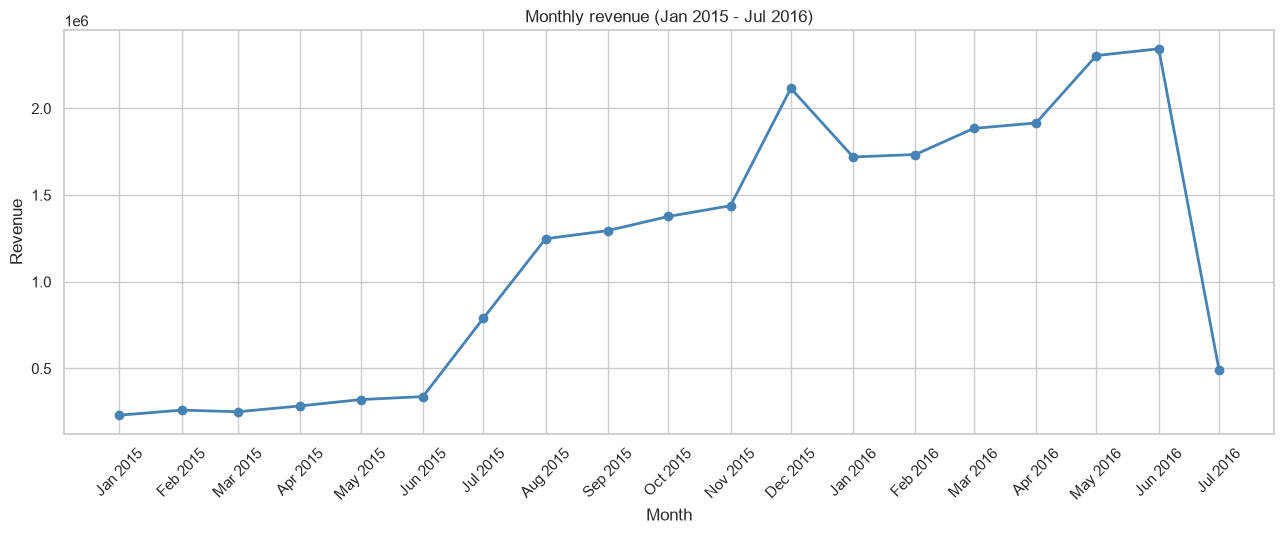

In [18]:
plt.figure(figsize=(13, 5.5))
plt.plot(monthly.index, monthly["Revenue"], marker="o", color="steelblue", linewidth=2)
plt.title("Monthly revenue (Jan 2015 - Jul 2016)")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(monthly.index, monthly.index.strftime("%b %Y"), rotation=45)
plt.tight_layout()
plt.show()

In [19]:
print("Highest revenue month:", monthly["Revenue"].idxmax().strftime("%b %Y"), round(monthly["Revenue"].max()))
print("Lowest revenue month:", monthly["Revenue"].idxmin().strftime("%b %Y"), round(monthly["Revenue"].min()))
print("Average monthly revenue:", round(monthly["Revenue"].mean()))
print()
print("Month-over-month change (%):")
print((monthly["Revenue"].pct_change() * 100).round(1).to_string())

Highest revenue month: Jun 2016 2344229
Lowest revenue month: Jan 2015 230549
Average monthly revenue: 1176030

Month-over-month change (%):
YearMonth
2015-01-01      NaN
2015-02-01     12.7
2015-03-01     -3.7
2015-04-01     13.5
2015-05-01     12.8
2015-06-01      5.3
2015-07-01    133.6
2015-08-01     58.2
2015-09-01      3.8
2015-10-01      6.3
2015-11-01      4.5
2015-12-01     47.1
2016-01-01    -18.7
2016-02-01      0.8
2016-03-01      8.7
2016-04-01      1.7
2016-05-01     20.3
2016-06-01      1.7
2016-07-01    -79.0
Freq: MS


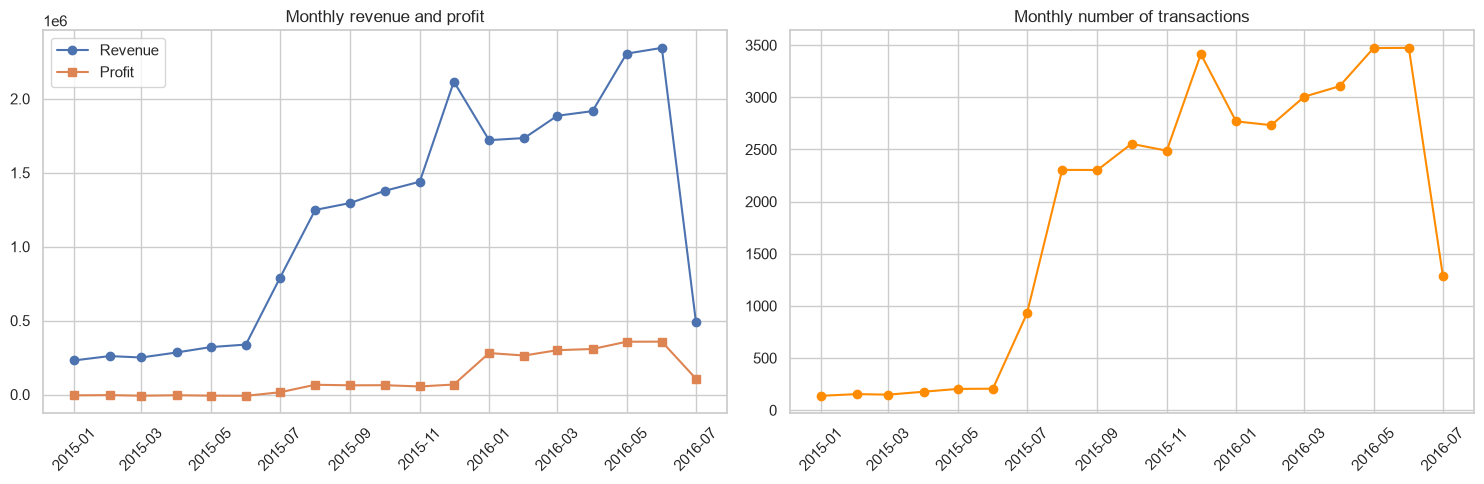

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].plot(monthly.index, monthly["Revenue"], marker="o", label="Revenue")
ax[0].plot(monthly.index, monthly["Profit"], marker="s", label="Profit")
ax[0].set_title("Monthly revenue and profit")
ax[0].legend()
ax[0].tick_params(axis="x", rotation=45)

ax[1].plot(monthly.index, monthly["Transactions"], marker="o", color="darkorange")
ax[1].set_title("Monthly number of transactions")
ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [21]:
data["Quarter"] = data["Date"].dt.to_period("Q")

quarterly = data.groupby("Quarter").agg(
    Revenue=("Revenue", "sum"),
    Profit=("Profit", "sum"),
    Transactions=("Revenue", "size"),
    Months=("YearMonth", "nunique")
)
quarterly.round(0)

,Revenue,Profit,Transactions,Months
Quarter,,,,
2015Q1,740764.0,-18023.0,441,3
2015Q2,942528.0,-21439.0,587,3
2015Q3,3332485.0,143202.0,5535,3
2015Q4,4931994.0,184880.0,8456,3
2016Q1,5339426.0,843621.0,8508,3
2016Q2,6565767.0,1022209.0,10052,3
2016Q3,491612.0,107152.0,1287,1


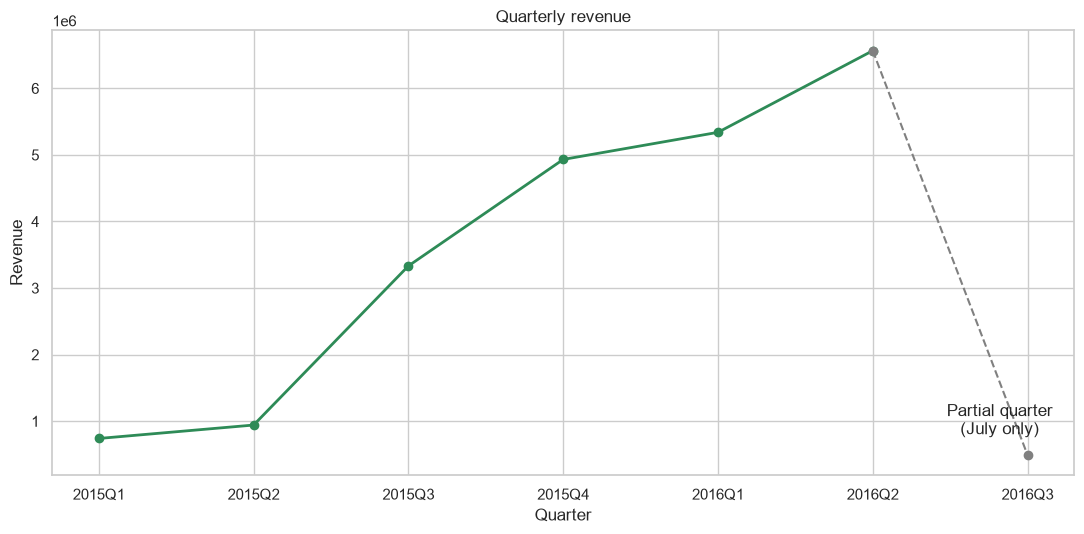

In [22]:
labels = quarterly.index.astype(str)
full = quarterly["Months"] == 3

plt.figure(figsize=(11, 5.5))
plt.plot(labels[full], quarterly.loc[full, "Revenue"], marker="o", color="seagreen", linewidth=2)
if (~full).any():
    last_full = quarterly.index[full][-1]
    partial = quarterly.index[~full][0]
    plt.plot([str(last_full), str(partial)],
             [quarterly.loc[last_full, "Revenue"], quarterly.loc[partial, "Revenue"]],
             linestyle="--", marker="o", color="gray")
    plt.annotate("Partial quarter\n(July only)", (str(partial), quarterly.loc[partial, "Revenue"]),
                 textcoords="offset points", xytext=(-20, 15), ha="center")
plt.title("Quarterly revenue")
plt.xlabel("Quarter")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

In [23]:
jan_jul = data[data["Date"].dt.month <= 7]
yoy = jan_jul.groupby("Year").agg(
    Revenue=("Revenue", "sum"),
    Profit=("Profit", "sum"),
    Transactions=("Revenue", "size")
)
yoy.loc["Change %"] = ((yoy.loc[2016] / yoy.loc[2015] - 1) * 100).round(1)
yoy.round(1)

,Revenue,Profit,Transactions
Year,,,
2015,2472346.0,-24358.0,1956.0
2016,12396805.0,1972982.0,19847.0
Change %,401.4,-8199.9,914.7


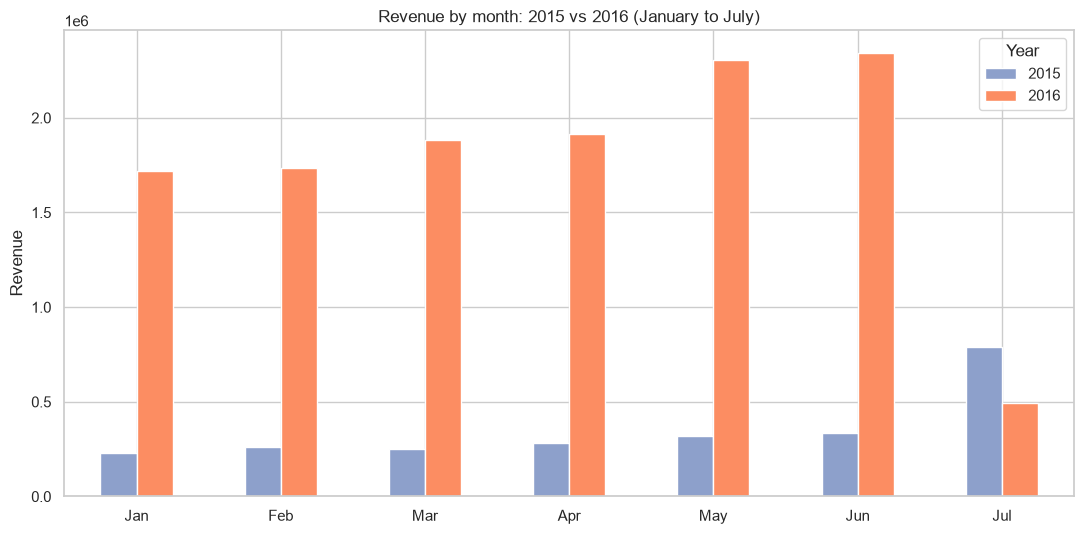

In [24]:
pivot = jan_jul.pivot_table(index=jan_jul["Date"].dt.month, columns="Year", values="Revenue", aggfunc="sum")
pivot.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul"]

pivot.plot(kind="bar", figsize=(11, 5.5), color=["#8da0cb", "#fc8d62"])
plt.title("Revenue by month: 2015 vs 2016 (January to July)")
plt.xlabel("")
plt.ylabel("Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [25]:
m2015 = monthly[monthly.index.year == 2015]["Revenue"]
print("Share of 2015 revenue by month (%):")
print((m2015 / m2015.sum() * 100).round(1).rename(lambda d: d.strftime("%b")).to_string())

Share of 2015 revenue by month (%):
YearMonth
Jan     2.3
Feb     2.6
Mar     2.5
Apr     2.9
May     3.2
Jun     3.4
Jul     7.9
Aug    12.5
Sep    13.0
Oct    13.8
Nov    14.5
Dec    21.3


In [26]:
daily = data.groupby("Date").size()
print("June 2016:", daily["2016-06-01":"2016-06-30"].agg(["count", "mean", "max"]).round(1).to_dict())
print("July 2016:", daily["2016-07-01":"2016-07-31"].agg(["count", "mean", "max"]).round(1).to_dict())
print("July 2015:", daily["2015-07-01":"2015-07-31"].agg(["count", "mean", "max"]).round(1).to_dict())

June 2016: {'count': 30.0, 'mean': 115.8, 'max': 172.0}
July 2016: {'count': 31.0, 'mean': 41.5, 'max': 72.0}
July 2015: {'count': 31.0, 'mean': 29.9, 'max': 53.0}


In [27]:
h1 = data[data["Date"].dt.month <= 6]
yoy = h1.groupby("Year").agg(
    Revenue=("Revenue", "sum"),
    Profit=("Profit", "sum"),
    Transactions=("Revenue", "size")
)
yoy.loc["Change %"] = ((yoy.loc[2016] / yoy.loc[2015] - 1) * 100).round(1)
yoy.round(1)

,Revenue,Profit,Transactions
Year,,,
2015,1683292.0,-39462.0,1028.0
2016,11905193.0,1865830.0,18560.0
Change %,607.3,-4828.2,1705.4


In [28]:
print(pd.crosstab(data["Quarter"], data["Country"]))

Country  France  Germany  United Kingdom  United States
Quarter                                                
2015Q1       81       82             104            174
2015Q2      121      110             105            251
2015Q3      839      804            1038           2854
2015Q4     1152     1143            1595           4566
2016Q1     1312     1293            1560           4343
2016Q2     1487     1604            1822           5139
2016Q3      176      165             197            749


In [29]:
print(pd.crosstab(data["Quarter"], data["Product Category"], normalize="index").mul(100).round(1))
q = data.groupby("Quarter")[["Revenue", "Profit"]].sum()
print((q["Profit"] / q["Revenue"] * 100).round(1).rename("Profit margin %"))
print(data.groupby("Quarter")["Revenue"].mean().round(0).rename("Avg revenue per transaction"))

Product Category  Accessories  Bikes  Clothing
Quarter                                       
2015Q1                    0.0  100.0       0.0
2015Q2                    0.0  100.0       0.0
2015Q3                   65.4   19.6      15.0
2015Q4                   66.2   19.0      14.8
2016Q1                   67.2   17.2      15.6
2016Q2                   65.1   19.0      15.9
2016Q3                   81.8    0.0      18.2
Quarter
2015Q1    -2.4
2015Q2    -2.3
2015Q3     4.3
2015Q4     3.7
2016Q1    15.8
2016Q2    15.6
2016Q3    21.8
Freq: Q-DEC, Name: Profit margin %, dtype: float64
Quarter
2015Q1    1680.0
2015Q2    1606.0
2015Q3     602.0
2015Q4     583.0
2016Q1     628.0
2016Q2     653.0
2016Q3     382.0
Freq: Q-DEC, Name: Avg revenue per transaction, dtype: float64


In [30]:
bikes = data[data["Product Category"] == "Bikes"]
print("Last bike sale:", bikes["Date"].max().date(), "| Last sale overall:", data["Date"].max().date())
bm = bikes.groupby("YearMonth").agg(Revenue=("Revenue", "sum"), Transactions=("Revenue", "size"))
bm.index = bm.index.to_timestamp()
bm.round(0)

Last bike sale: 2016-06-30 | Last sale overall: 2016-07-31


,Revenue,Transactions
YearMonth,,
2015-01-01,230549.0,138
2015-02-01,259857.0,154
2015-03-01,250358.0,149
2015-04-01,284143.0,177
2015-05-01,320629.0,204
2015-06-01,337756.0,206
2015-07-01,564856.0,355
2015-08-01,537102.0,357
2015-09-01,556606.0,372


In [31]:
b_h1 = bikes[bikes["Date"].dt.month <= 6]
b_yoy = b_h1.groupby("Year").agg(Revenue=("Revenue", "sum"), Profit=("Profit", "sum"), Transactions=("Revenue", "size"))
print(b_yoy.round(0))
print("Revenue change %:", round((b_yoy.loc[2016, "Revenue"] / b_yoy.loc[2015, "Revenue"] - 1) * 100, 1))
print("Transactions change %:", round((b_yoy.loc[2016, "Transactions"] / b_yoy.loc[2015, "Transactions"] - 1) * 100, 1))

        Revenue    Profit  Transactions
Year                                   
2015  1683292.0  -39462.0          1028
2016  5722257.0  512935.0          3372
Revenue change %: 239.9
Transactions change %: 228.0


In [32]:
cat_q = data.groupby(["Quarter", "Product Category"])[["Revenue", "Profit"]].sum()
cat_q["Margin %"] = (cat_q["Profit"] / cat_q["Revenue"] * 100).round(1)
print(cat_q["Margin %"].unstack())
print(cat_q["Revenue"].unstack().round(0))

Product Category  Accessories  Bikes  Clothing
Quarter                                       
2015Q1                    NaN   -2.4       NaN
2015Q2                    NaN   -2.3       NaN
2015Q3                   12.1   -2.6       9.1
2015Q4                   12.2   -3.8       8.7
2016Q1                   22.5    8.9      20.3
2016Q2                   22.6    9.0      20.6
2016Q3                   22.5    NaN      20.1
Product Category  Accessories      Bikes   Clothing
Quarter                                            
2015Q1                    NaN   740764.0        NaN
2015Q2                    NaN   942528.0        NaN
2015Q3              1137782.0  1658564.0   536139.0
2015Q4              1687985.0  2422242.0   821767.0
2016Q1              1972725.0  2491683.0   875018.0
2016Q2              2276854.0  3230574.0  1058339.0
2016Q3               345318.0        NaN   146294.0


In [33]:
data_full = data[(data["Date"] >= "2015-07-01") & (data["Date"] <= "2016-06-30")].copy()
print(data_full.shape)
print(data_full.groupby("YearMonth")["Product Category"].nunique().to_string())

(32551, 18)
YearMonth
2015-07    3
2015-08    3
2015-09    3
2015-10    3
2015-11    3
2015-12    3
2016-01    3
2016-02    3
2016-03    3
2016-04    3
2016-05    3
2016-06    3
Freq: M


In [34]:
top_subs = data_full["Sub Category"].value_counts().head(4).index
sub_avg = data_full.groupby(["Sub Category", "Quarter"])[["Unit Price", "Unit Cost"]].mean().round(2)
for s in top_subs:
    print(s)
    print(sub_avg.loc[s])
    print()

Tires and Tubes
         Unit Price  Unit Cost
Quarter                       
2015Q3       153.67     135.11
2015Q4       151.39     133.58
2016Q1       160.13     125.19
2016Q2       161.32     125.50

Bottles and Cages
         Unit Price  Unit Cost
Quarter                       
2015Q3        76.06      67.47
2015Q4        75.68      66.51
2016Q1        85.34      66.22
2016Q2        88.04      68.67

Helmets
         Unit Price  Unit Cost
Quarter                       
2015Q3       382.10     334.36
2015Q4       359.14     314.08
2016Q1       417.11     320.36
2016Q2       418.82     322.55

Mountain Bikes
         Unit Price  Unit Cost
Quarter                       
2015Q3      1139.24    1185.76
2015Q4      1020.37    1056.53
2016Q1      1195.72    1084.47
2016Q2      1187.59    1084.79



In [35]:
mix = pd.DataFrame({
    "Transactions %": data_full["Product Category"].value_counts(normalize=True).mul(100),
    "Revenue %": data_full.groupby("Product Category")["Revenue"].sum() / data_full["Revenue"].sum() * 100,
    "Profit %": data_full.groupby("Product Category")["Profit"].sum() / data_full["Profit"].sum() * 100,
}).round(1)
mix

,Transactions %,Revenue %,Profit %
Product Category,,,
Accessories,66.0,35.1,59.3
Bikes,18.6,48.6,17.2
Clothing,15.4,16.3,23.5


### Observations: Time Series

**Monthly trend**
- Monthly revenue grew from **230,549 in January 2015** (the lowest month) to a peak of **2,344,229 in June 2016**, about 10 times higher. The average month brought in 1,176,030.
- Growth was **not smooth**. Revenue was flat at about 230,000 to 340,000 a month from January to June 2015, then jumped **+133.6% in July 2015** and **+58.2% in August 2015**, after which it rose by 4% to 6% a month.
- **That jump is a change in the product range recorded in the data.** In 2015 Q1 and Q2 every transaction is a Bike. From 2015 Q3 the mix becomes 65.4% Accessories, 19.6% Bikes and 15.0% Clothing. Transactions rose from 206 in June 2015 to 2,304 in August 2015, but revenue per transaction fell, so the jump reflects new products appearing, not only more customers buying.
- **Bikes alone grew steadily**: monthly bike revenue rose from 230,549 (January 2015) to 337,756 (June 2015), +46.5%, and reached 1,199,808 in June 2016.
- **December 2015 spiked** to 2,116,097 (+47.1% over November). The spike is also visible in bikes alone (1,115,613, +61.3% over November, with 746 transactions against 455), followed by a **fall of 30.6% in bike revenue in January 2016**. This looks like a year-end peak, but with only one December in the data it cannot be confirmed as seasonality.
- From January to June 2016, revenue rose from 1,720,072 to 2,344,229 (+36.3%), a period when all three categories were present.
- **July 2016 (491,612, -79.0% vs June) is a data problem, not a sales collapse.** Sales are recorded on all 31 days, but the last bike sale in the data is **30 June 2016**, so bikes, the highest-revenue category, are missing for the whole month. Daily transactions average 41.5 against 115.8 in June. The month is excluded from all trend and growth conclusions.

**Quarterly trend**

| Quarter | Revenue | Profit | Margin | Transactions | Avg revenue per transaction | Revenue growth vs previous quarter |
|---|---|---|---|---|---|---|
| 2015 Q1 | 740,764 | -18,023 | -2.4% | 441 | 1,680 | n/a |
| 2015 Q2 | 942,528 | -21,439 | -2.3% | 587 | 1,606 | +27.2% |
| 2015 Q3 | 3,332,485 | 143,202 | 4.3% | 5,535 | 602 | +253.6% |
| 2015 Q4 | 4,931,994 | 184,880 | 3.7% | 8,456 | 583 | +48.0% |
| 2016 Q1 | 5,339,426 | 843,621 | 15.8% | 8,508 | 628 | +8.3% |
| 2016 Q2 | 6,565,767 | 1,022,209 | 15.6% | 10,052 | 653 | +23.0% |
| 2016 Q3 | 491,612 | 107,152 | 21.8% | 1,287 | 382 | not comparable (July only, no bike sales) |

- Revenue rose in every full quarter, from 740,764 to 6,565,767 in 2016 Q2. The biggest jump was 2015 Q3 (+253.6%), when Accessories and Clothing first appear.
- **2016 Q3 is not comparable** with other quarters: it contains only July, and it has no bike sales.

**Year over year (January to June)**

| Period | Revenue | Profit | Transactions |
|---|---|---|---|
| H1 2015 (Bikes only) | 1,683,292 | -39,462 | 1,028 |
| H1 2016 (all categories) | 11,905,193 | 1,865,830 | 18,560 |
| Headline change | +607.3% | loss to profit | +1,705.4% |

- **The headline comparison is not like for like**, because H1 2015 contains Bikes only while H1 2016 contains all three categories. The +607% overstates real growth.
- **Bikes only (the one category present in both periods):**

| Bikes, H1 | Revenue | Profit | Transactions |
|---|---|---|---|
| 2015 | 1,683,292 | -39,462 | 1,028 |
| 2016 | 5,722,257 | 512,935 | 3,372 |
| Change | **+239.9%** | loss to profit | **+228.0%** |

  Revenue per bike transaction rose only about 3.6% (1,637 to 1,697), so the growth came almost entirely from **more orders, not higher prices per order**.
- Revenue for January to June 2016 alone was about 20% higher than the whole of 2015 (9,947,771). 83% of 2015 revenue came in the last six months of the year, so 2015 is a ramp-up year and its monthly shares (January 2.3% rising to December 21.3%) reflect growth and the addition of categories, not seasonality.

**Profit and margin**
- Profit was **negative from January to June 2015** (-39,462 in total, margins of -2.4% and -2.3%), when only Bikes were sold. It became positive from July 2015 (4.3% in Q3 and 3.7% in Q4), and rose to **15.8% in 2016 Q1 and 15.6% in Q2**.
- **Margins by category:**

| Category | 2015 Q3 | 2015 Q4 | 2016 Q1 | 2016 Q2 |
|---|---|---|---|---|
| Accessories | 12.1% | 12.2% | 22.5% | 22.6% |
| Clothing | 9.1% | 8.7% | 20.3% | 20.6% |
| Bikes | -2.6% | -3.8% | 8.9% | 9.0% |

- **All three categories gained 10 to 13 margin points between 2015 Q4 and 2016 Q1**, while the category mix stayed almost unchanged (66.2% / 19.0% / 14.8% against 67.2% / 17.2% / 15.6%). The margin jump is therefore **not a product-mix effect**; it points to a business-wide change at the start of 2016.
- The cause is mainly **higher prices**. Between 2015 Q4 and 2016 Q1 the average unit price rose by 5.8% (Tires and Tubes), 12.8% (Bottles and Cages), 16.1% (Helmets) and 17.2% (Mountain Bikes), while average unit costs stayed roughly flat (from -6.3% to +2.6%).
- **Mountain Bikes were sold below cost on average in 2015** (price 1,139 vs cost 1,186 in Q3; 1,020 vs 1,057 in Q4), which explains the bike losses, and above cost from 2016 (1,196 vs 1,084 in Q1).
- These are averages within each sub-category, so a change in the model mix could contribute. The pattern is consistent with a price increase but does not prove it.
- Bikes **lost money in every quarter of 2015** (-2.3% to -3.8%) and only became profitable in 2016, at about 9%.
- The 2016 Q3 margin of 21.8% is not meaningful, because bikes are missing from that month.

**Average order size**
- Average revenue per transaction fell from about **1,680 (2015 Q1) to 602 (2015 Q3)**, then stayed between 583 and 653. This is consistent with low-priced Accessories and Clothing joining the high-priced Bikes. Transactions rose far faster than revenue for the same reason.

**Geography**
- All four countries appear in every quarter, so new markets do not explain the mid-2015 jump. The United States' share of transactions rose from about 39% in 2015 Q1 (174 of 441) to about 51% to 54% from 2015 Q3 onward.

### Impact on the rest of the analysis
Because the product range changes in July 2015 and bike data is missing in July 2016, comparisons of products and categories use **July 2015 to June 2016** (12 months in which all three categories are present, 32,551 transactions). Demographic analysis uses all rows.

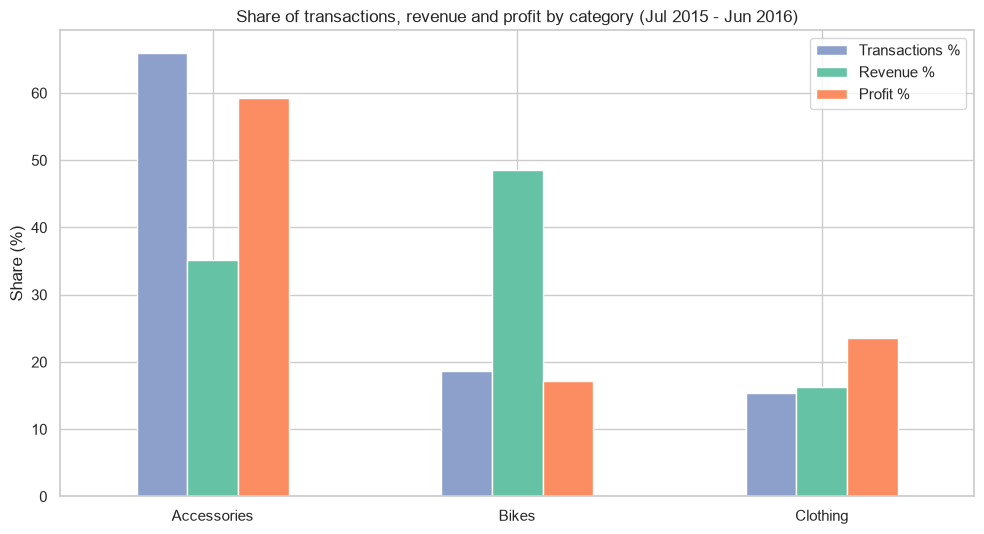

In [36]:
share = mix[["Transactions %", "Revenue %", "Profit %"]]
share.plot(kind="bar", figsize=(10, 5.5), color=["#8da0cb", "#66c2a5", "#fc8d62"])
plt.title("Share of transactions, revenue and profit by category (Jul 2015 - Jun 2016)")
plt.xlabel("")
plt.ylabel("Share (%)")
plt.xticks(rotation=0)
plt.legend(title="")
plt.tight_layout()
plt.show()

### Observations: Where Does the Profit Come From? (Additional Visualisation)
- **Revenue and profit tell different stories.** Bikes generate **48.6% of revenue but only 17.2% of profit**, while Accessories generate 35.1% of revenue and **59.3% of profit**. Clothing contributes 16.3% of revenue and 23.5% of profit.
- Accessories are 66.0% of all transactions, so they are the volume and profit engine, even though each sale is small.
- Bikes were loss-making throughout 2015 (margins of −2.3% to −3.8%) and reached only about 9% in 2016, against about 22% for Accessories and about 20% for Clothing.
- **Implication:** judging categories by revenue alone would overstate Bikes and understate Accessories. Decisions about promotions, stock and pricing should look at profit.

In [37]:
bins = [16, 24, 34, 44, 54, 64, 100]
labels = ["17-24", "25-34", "35-44", "45-54", "55-64", "65+"]
data["Age Group"] = pd.cut(data["Customer Age"], bins=bins, labels=labels)
data_full = data[(data["Date"] >= "2015-07-01") & (data["Date"] <= "2016-06-30")].copy()
print(data["Age Group"].value_counts().sort_index())

Age Group
17-24     5157
25-34    11606
35-44    10075
45-54     5730
55-64     2030
65+        268
Name: count, dtype: int64


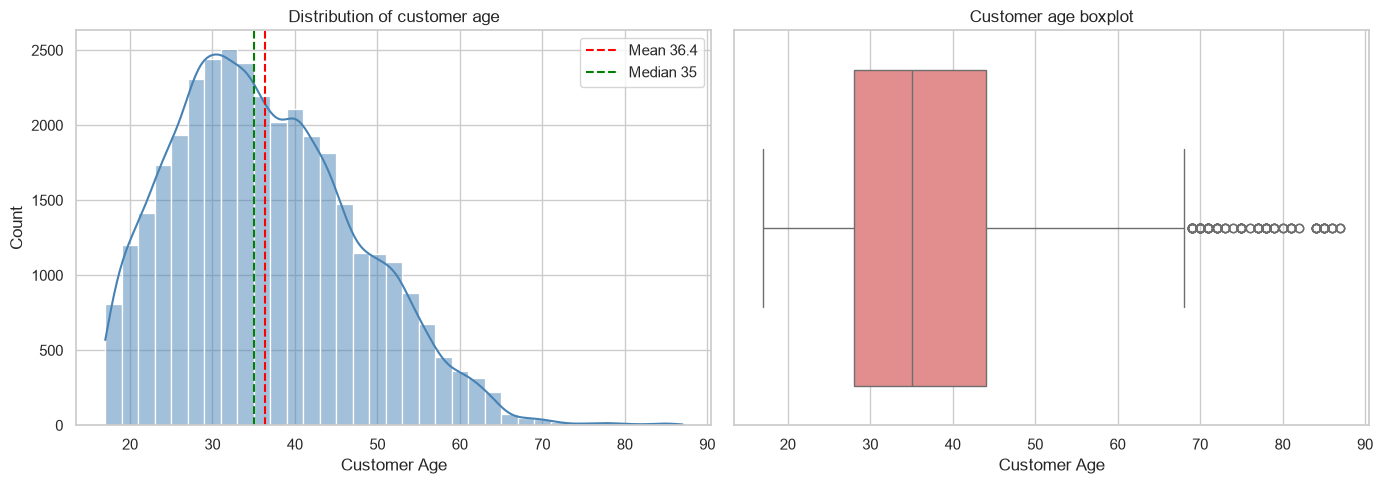

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data["Customer Age"], bins=35, kde=True, ax=ax[0], color="steelblue")
ax[0].axvline(data["Customer Age"].mean(), color="red", linestyle="--", label=f"Mean {data['Customer Age'].mean():.1f}")
ax[0].axvline(data["Customer Age"].median(), color="green", linestyle="--", label=f"Median {data['Customer Age'].median():.0f}")
ax[0].set_title("Distribution of customer age")
ax[0].legend()

sns.boxplot(x=data["Customer Age"], ax=ax[1], color="lightcoral")
ax[1].set_title("Customer age boxplot")
plt.tight_layout()
plt.show()

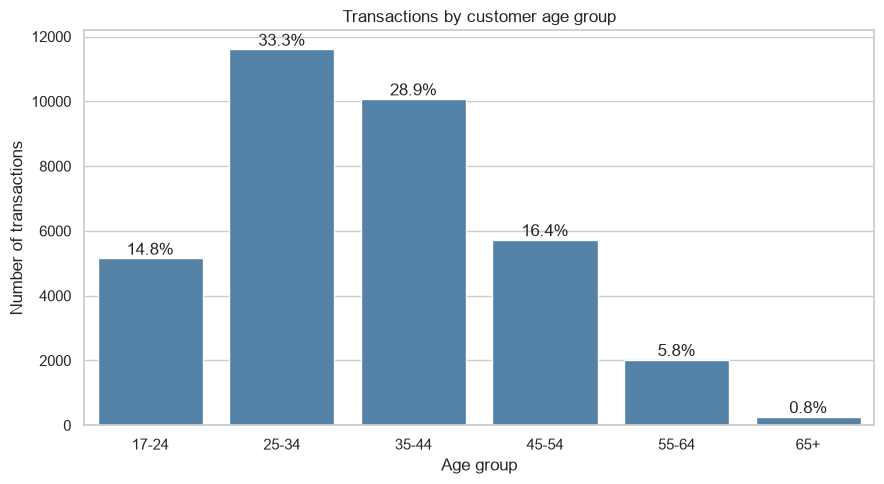

Age Group
17-24    14.8
25-34    33.3
35-44    28.9
45-54    16.4
55-64     5.8
65+       0.8
Name: count, dtype: float64


In [39]:
ag = data["Age Group"].value_counts().sort_index()
ag_pct = (ag / ag.sum() * 100).round(1)

plt.figure(figsize=(9, 5))
sns.barplot(x=ag.index.astype(str), y=ag.values, color="steelblue")
for i, (v, p) in enumerate(zip(ag.values, ag_pct.values)):
    plt.text(i, v, f"{p}%", ha="center", va="bottom")
plt.title("Transactions by customer age group")
plt.xlabel("Age group")
plt.ylabel("Number of transactions")
plt.tight_layout()
plt.show()
print(ag_pct)

### Observations: Customer Age

*Counts are transactions, not unique customers, because the dataset has no customer ID.*

- **The typical customer is in their early to mid 30s.** The mean age is 36.4, the median 35 and the most frequent age 31, with the middle half of transactions coming from customers aged roughly 28 to 44. The distribution is mildly right-skewed (skew 0.52), peaking around age 30, with a thin tail of older customers.
- **Outliers:** the boxplot flags customers above about 68 years old (up to 87) as outliers, but they are very rare.

| Age group | Transactions | Share |
|---|---|---|
| 17-24 | 5,157 | 14.8% |
| 25-34 | 11,606 | **33.3%** |
| 35-44 | 10,075 | **28.9%** |
| 45-54 | 5,730 | 16.4% |
| 55-64 | 2,030 | 5.8% |
| 65+ | 268 | 0.8% |

- **The 25-44 range is the core market**: it makes up **62.2% of all transactions** (21,681 of 34,866), and 25-54 makes up 78.6%.
- **Under-35s account for 48.1%** of transactions, so the customer base skews young.
- **Customers aged 55 and over are only 6.6%** of transactions, and the 65+ group (268 transactions) is too small for reliable conclusions.

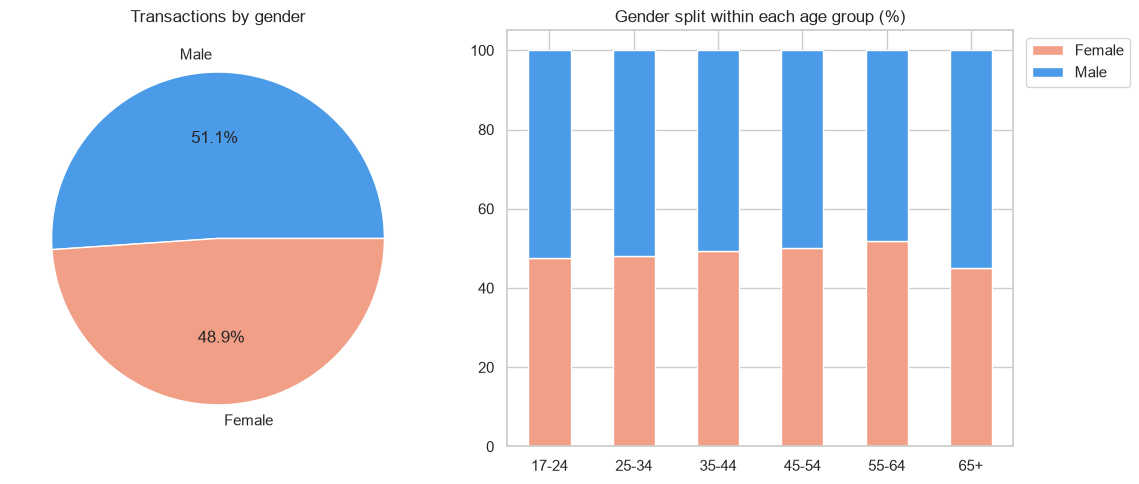

Customer Gender     F     M
Age Group                  
17-24            47.5  52.5
25-34            48.1  51.9
35-44            49.4  50.6
45-54            50.1  49.9
55-64            51.9  48.1
65+              45.1  54.9


In [46]:
g = data["Customer Gender"].value_counts()

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].pie(g, labels=["Male" if x == "M" else "Female" for x in g.index], autopct="%1.1f%%", colors=["#4c9be8", "#f29f87"])
ax[0].set_title("Transactions by gender")

gender_age = pd.crosstab(data["Age Group"], data["Customer Gender"], normalize="index").mul(100).round(1)
gender_age.plot(kind="bar", stacked=True, ax=ax[1], color=["#f29f87", "#4c9be8"])
ax[1].legend(["Female", "Male"], loc="upper left", bbox_to_anchor=(1.01, 1))
ax[1].set_title("Gender split within each age group (%)")
ax[1].set_xlabel("")
ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()
print(gender_age)

### Observations: Gender

- **Transactions are split almost evenly: 51.1% male and 48.9% female.**
- **The split holds across age groups.** The male share stays between 48.1% and 54.9% in every group:

| Age group | Female | Male |
|---|---|---|
| 17-24 | 47.5% | 52.5% |
| 25-34 | 48.1% | 51.9% |
| 35-44 | 49.4% | 50.6% |
| 45-54 | 50.1% | 49.9% |
| 55-64 | 51.9% | 48.1% |
| 65+ | 45.1% | 54.9% |

- The female share rises gently with age from 47.5% (17-24) to 51.9% (55-64). The 65+ figure (45.1%) rests on only 268 transactions and should not be over-read.
- Neither gender dominates any age group, so there is no single gender to target.

In [41]:
by_gender = data_full.groupby("Customer Gender").agg(
    Transactions=("Revenue", "size"),
    Revenue=("Revenue", "sum"),
    Profit=("Profit", "sum"),
    Avg_Revenue=("Revenue", "mean"),
    Median_Revenue=("Revenue", "median"),
    Avg_Quantity=("Quantity", "mean")
)
by_gender["Margin %"] = (by_gender["Profit"] / by_gender["Revenue"] * 100).round(1)
by_gender["Revenue share %"] = (by_gender["Revenue"] / by_gender["Revenue"].sum() * 100).round(1)
by_gender.round(1)

,Transactions,Revenue,Profit,Avg_Revenue,Median_Revenue,Avg_Quantity,Margin %,Revenue share %
Customer Gender,,,,,,,,
F,15886,9873874.0,1067569.0,621.5,290.0,2.0,10.8,49.0
M,16665,10295798.0,1126343.0,617.8,309.0,2.0,10.9,51.0


In [42]:
by_age = data_full.groupby("Age Group", observed=True).agg(
    Transactions=("Revenue", "size"),
    Revenue=("Revenue", "sum"),
    Profit=("Profit", "sum"),
    Avg_Revenue=("Revenue", "mean"),
    Median_Revenue=("Revenue", "median")
)
by_age["Margin %"] = (by_age["Profit"] / by_age["Revenue"] * 100).round(1)
by_age["Revenue share %"] = (by_age["Revenue"] / by_age["Revenue"].sum() * 100).round(1)
by_age.round(1)

,Transactions,Revenue,Profit,Avg_Revenue,Median_Revenue,Margin %,Revenue share %
Age Group,,,,,,,
17-24,4838,2332281.0,278764.0,482.1,206.5,12.0,11.6
25-34,10801,6917851.0,739376.0,640.5,347.0,10.7,34.3
35-44,9398,6332955.0,695370.0,673.9,341.5,11.0,31.4
45-54,5334,3376599.0,357368.0,633.0,283.0,10.6,16.7
55-64,1932,1095944.0,105993.0,567.3,261.0,9.7,5.4
65+,248,114042.0,17041.0,459.8,169.0,14.9,0.6


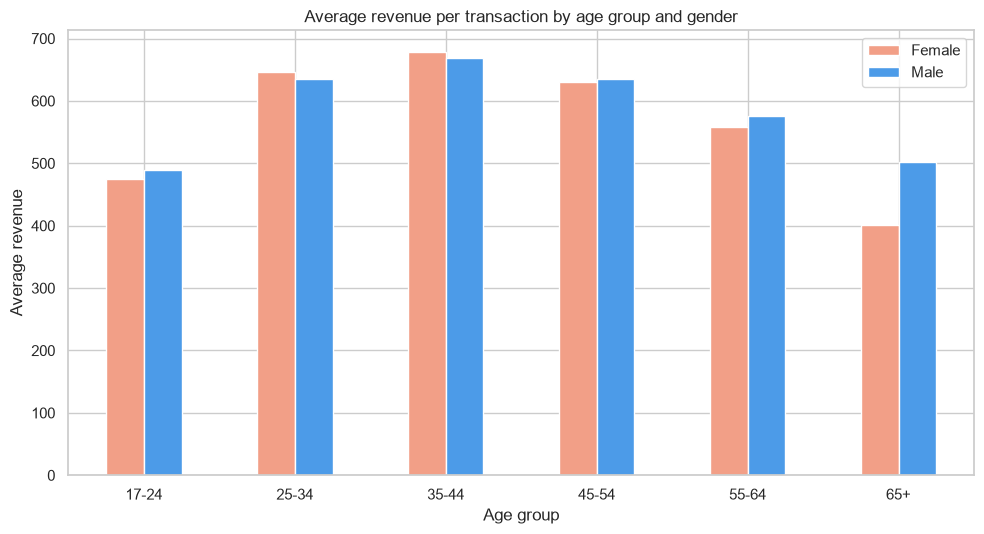

Customer Gender      F      M
Age Group                    
17-24            474.7  488.7
25-34            646.2  635.2
35-44            679.0  668.8
45-54            631.0  635.1
55-64            558.7  576.4
65+              401.8  502.4


In [43]:
pivot_avg = data_full.pivot_table(index="Age Group", columns="Customer Gender", values="Revenue", aggfunc="mean", observed=True)
pivot_avg.rename(columns={"F": "Female", "M": "Male"}).plot(kind="bar", figsize=(10, 5.5), color=["#f29f87", "#4c9be8"])
plt.title("Average revenue per transaction by age group and gender")
plt.xlabel("Age group")
plt.ylabel("Average revenue")
plt.xticks(rotation=0)
plt.legend(title="")
plt.tight_layout()
plt.show()
print(pivot_avg.round(1))

Share of each age group's transactions by category (%):
Product Category  Accessories  Bikes  Clothing
Age Group                                     
17-24                    71.6   12.2      16.3
25-34                    62.3   22.4      15.4
35-44                    64.4   20.4      15.3
45-54                    68.8   16.5      14.7
55-64                    71.0   13.0      16.0
65+                      80.2    5.6      14.1

Share of each gender's transactions by category (%):
Product Category  Accessories  Bikes  Clothing
Customer Gender                               
F                        66.0   18.9      15.1
M                        66.0   18.3      15.7


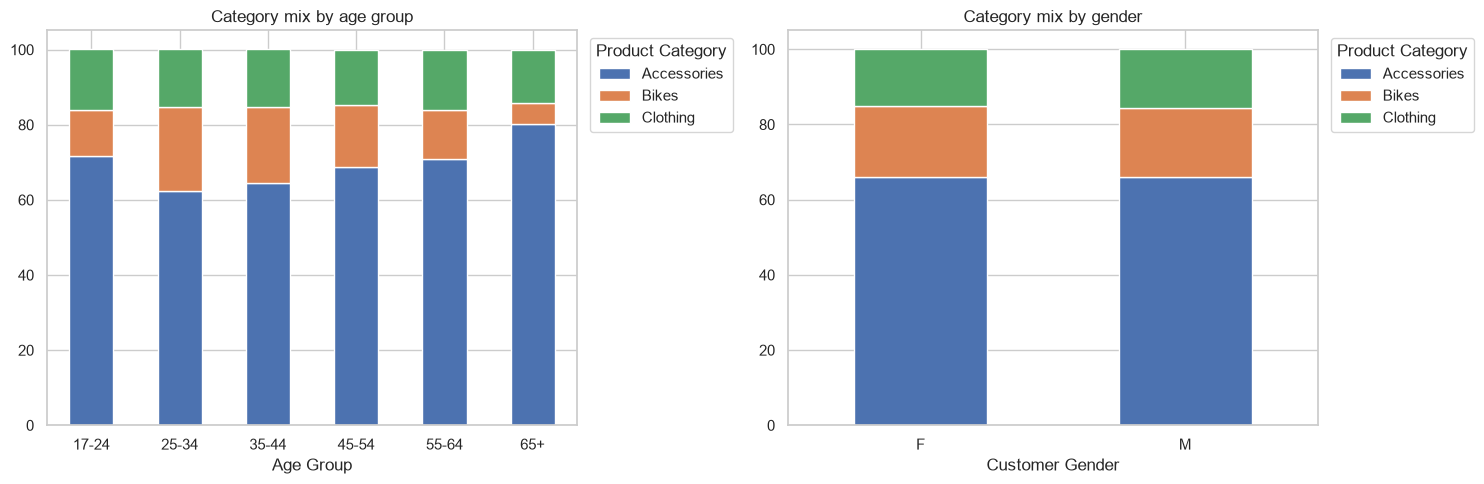

In [47]:
cat_age = pd.crosstab(data_full["Age Group"], data_full["Product Category"], normalize="index").mul(100).round(1)
cat_gender = pd.crosstab(data_full["Customer Gender"], data_full["Product Category"], normalize="index").mul(100).round(1)
print("Share of each age group's transactions by category (%):")
print(cat_age)
print()
print("Share of each gender's transactions by category (%):")
print(cat_gender)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
cat_age.plot(kind="bar", stacked=True, ax=ax[0])
ax[0].set_title("Category mix by age group")
ax[0].tick_params(axis="x", rotation=0)
cat_gender.plot(kind="bar", stacked=True, ax=ax[1])
ax[1].set_title("Category mix by gender")
ax[1].tick_params(axis="x", rotation=0)
ax[0].legend(title="Product Category", loc="upper left", bbox_to_anchor=(1.01, 1))
ax[1].legend(title="Product Category", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

In [45]:
rev_age = by_age["Revenue share %"]
ag_pct_full = (data_full["Age Group"].value_counts(normalize=True).sort_index() * 100).round(1)
print(pd.DataFrame({"Transactions %": ag_pct_full, "Revenue %": rev_age}))

           Transactions %  Revenue %
Age Group                           
17-24                14.9       11.6
25-34                33.2       34.3
35-44                28.9       31.4
45-54                16.4       16.7
55-64                 5.9        5.4
65+                   0.8        0.6


### Observations: Spending and Category Preferences by Age and Gender

*These comparisons use the 12 complete months (July 2015 to June 2016, 32,551 transactions), because bikes are missing before July 2015 and after June 2016.*

**Gender makes almost no difference to spending**

| | Transactions | Revenue | Profit | Avg revenue | Median revenue | Margin | Revenue share |
|---|---|---|---|---|---|---|---|
| Female | 15,886 | 9,873,874 | 1,067,569 | 621.5 | 290 | 10.8% | 49.0% |
| Male | 16,665 | 10,295,798 | 1,126,343 | 617.8 | 309 | 10.9% | 51.0% |

- The average order is 621.5 for women and 617.8 for men (a 0.6% gap in women's favour), while the median is 309 for men and 290 for women (a 6.6% gap in men's favour). The gaps point in opposite directions and are small, so **there is no consistent spending difference between genders**.
- Both genders order 2.0 units on average and give a margin of about 10.8% to 10.9%. Males account for 51.0% of revenue and 51.3% of profit, in line with their 51.2% share of transactions.
- Category choice is also almost identical: Accessories 66.0% for both, Bikes 18.9% (female) vs 18.3% (male), Clothing 15.1% vs 15.7%.

**Age strongly affects spending**

| Age group | Transactions share | Revenue share | Avg revenue | Median revenue | Margin |
|---|---|---|---|---|---|
| 17-24 | 14.9% | 11.6% | 482.1 | 206.5 | 12.0% |
| 25-34 | 33.2% | 34.3% | 640.5 | 347.0 | 10.7% |
| 35-44 | 28.9% | 31.4% | **673.9** | 341.5 | 11.0% |
| 45-54 | 16.4% | 16.7% | 633.0 | 283.0 | 10.6% |
| 55-64 | 5.9% | 5.4% | 567.3 | 261.0 | 9.7% |
| 65+ | 0.8% | 0.6% | 459.8 | 169.0 | 14.9% |

- **Customers aged 35-44 spend the most per transaction (673.9, about 8.8% above the overall average of 619.6)**, followed by 25-34 (640.5) and 45-54 (633.0).
- **Customers aged 17-24 spend about 22% less per transaction** (482.1) and their median order is only 206.5. They make 14.9% of transactions but contribute only 11.6% of revenue.
- **The 25-44 groups are worth more than their volume suggests**: they are 62.1% of transactions but **65.7% of revenue**.
- Within each age group, men and women spend similar amounts (differences under 3% for ages 17 to 64). The 65+ gap (women 401.8, men 502.4) rests on 248 transactions and is not reliable.

**Why age matters: bikes**

| Age group | Accessories | Bikes | Clothing |
|---|---|---|---|
| 17-24 | 71.6% | 12.2% | 16.3% |
| 25-34 | 62.3% | **22.4%** | 15.4% |
| 35-44 | 64.4% | 20.4% | 15.3% |
| 45-54 | 68.8% | 16.5% | 14.7% |
| 55-64 | 71.0% | 13.0% | 16.0% |
| 65+ | 80.2% | 5.6% | 14.1% |

- The **share of bikes in each age group closely follows its average spend.** Bikes peak at 22.4% of transactions for 25-34 and 20.4% for 35-44, and fall to 12.2% for 17-24 and 5.6% for 65+. The ranking of age groups by bike share and by average revenue is the same except that the top two swap places.
- Since a bike costs far more than an accessory, **the age groups that buy more bikes spend more per order**. The same is true in reverse: customers over 65 buy mostly accessories (80.2%).
- Clothing is steady at 14% to 16% in every age group.

**Takeaways**
- The core customer is **25 to 44 years old, male or female** (62% of transactions, about 66% of revenue).
- **Gender is not a useful basis for targeting** in this dataset: spending, margin and category mix are the same for both.
- **Age is a useful basis**: younger (17-24) and older (55+) customers buy fewer bikes and spend less per order, so they represent growth or retention opportunities rather than the revenue core.

In [48]:
subcat = data_full.groupby(["Sub Category", "Product Category"]).agg(
    Units=("Quantity", "sum"),
    Transactions=("Revenue", "size"),
    Revenue=("Revenue", "sum"),
    Profit=("Profit", "sum"),
    Avg_Unit_Price=("Unit Price", "mean")
).reset_index()
subcat["Margin %"] = (subcat["Profit"] / subcat["Revenue"] * 100).round(1)
subcat["Revenue share %"] = (subcat["Revenue"] / subcat["Revenue"].sum() * 100).round(1)
subcat = subcat.sort_values("Units", ascending=False).reset_index(drop=True)
subcat.round(1)

,Sub Category,Product Category,Units,Transactions,Revenue,Profit,Avg_Unit_Price,Margin %,Revenue share %
0,Tires and Tubes,Accessories,20926,10477,2706209.0,476718.0,156.9,17.6,13.4
1,Bottles and Cages,Accessories,10262,5142,690393.0,125525.0,82.1,18.2,3.4
2,Helmets,Accessories,8063,4017,2635572.0,495777.0,396.0,18.8,13.1
3,Mountain Bikes,Bikes,4803,2389,4485028.0,170079.0,1137.8,3.8,22.2
4,Road Bikes,Bikes,4775,2342,2930125.0,112176.0,745.2,3.8,14.5
5,Jerseys,Clothing,3875,1924,1767628.0,286888.0,554.7,16.2,8.8
6,Caps,Clothing,2886,1456,245850.0,41604.0,104.7,16.9,1.2
7,Touring Bikes,Bikes,2673,1334,2387910.0,94808.0,1090.8,4.0,11.8
8,Fenders,Accessories,1385,705,303908.0,65834.0,276.6,21.7,1.5
9,Shorts,Clothing,1067,536,653447.0,80427.0,751.5,12.3,3.2


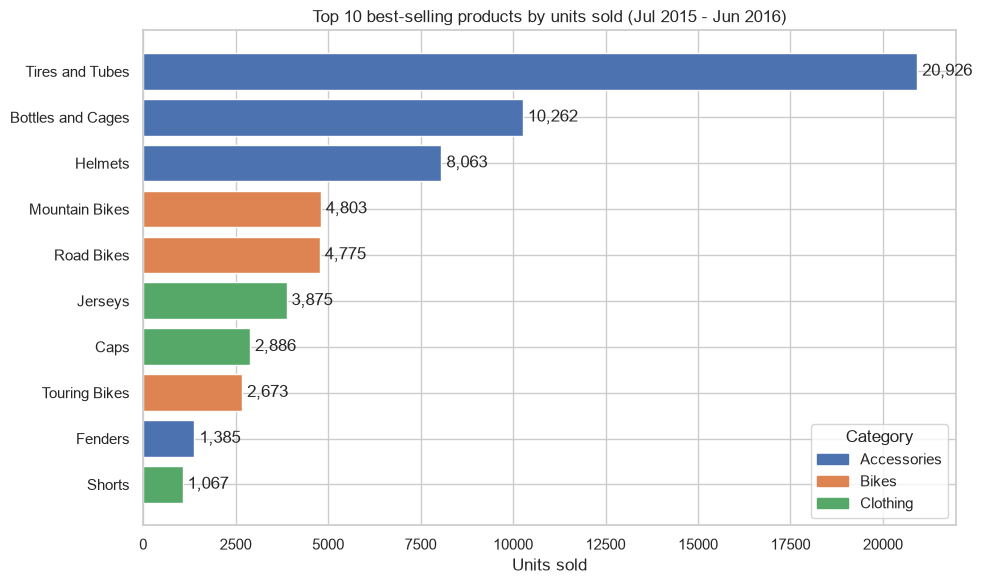

In [61]:
palette = {"Accessories": "#4c72b0", "Bikes": "#dd8452", "Clothing": "#55a868"}
top10 = subcat.head(10).iloc[::-1]

plt.figure(figsize=(10, 6))
bars = plt.barh(top10["Sub Category"], top10["Units"], color=top10["Product Category"].map(palette))
for b, v in zip(bars, top10["Units"]):
    plt.text(v, b.get_y() + b.get_height() / 2, f" {v:,}", va="center")
plt.title("Top 10 best-selling products by units sold (Jul 2015 - Jun 2016)")
plt.xlabel("Units sold")
plt.ylabel("")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()]
plt.legend(handles, palette.keys(), title="Category", loc="lower right")
plt.tight_layout()
plt.show()

In [50]:
print("Top 10 share of units:", round(subcat.head(10)["Units"].sum() / subcat["Units"].sum() * 100, 1), "%")
print("Top 3 share of units:", round(subcat.head(3)["Units"].sum() / subcat["Units"].sum() * 100, 1), "%")
print("Number of sub-categories:", len(subcat))

Top 10 share of units: 93.2 %
Top 3 share of units: 60.2 %
Number of sub-categories: 17


In [51]:
rank = subcat.set_index("Sub Category")[["Units", "Revenue", "Profit"]].copy()
for c in ["Units", "Revenue", "Profit"]:
    rank[c + " rank"] = rank[c].rank(ascending=False).astype(int)
rank[["Units rank", "Revenue rank", "Profit rank", "Units", "Revenue", "Profit"]].sort_values("Units rank").round(0)

,Units rank,Revenue rank,Profit rank,Units,Revenue,Profit
Sub Category,,,,,,
Tires and Tubes,1,3,2,20926,2706209.0,476718.0
Bottles and Cages,2,7,5,10262,690393.0,125525.0
Helmets,3,4,1,8063,2635572.0,495777.0
Mountain Bikes,4,1,4,4803,4485028.0,170079.0
Road Bikes,5,2,6,4775,2930125.0,112176.0
Jerseys,6,6,3,3875,1767628.0,286888.0
Caps,7,12,13,2886,245850.0,41604.0
Touring Bikes,8,5,7,2673,2387910.0,94808.0
Fenders,9,11,10,1385,303908.0,65834.0


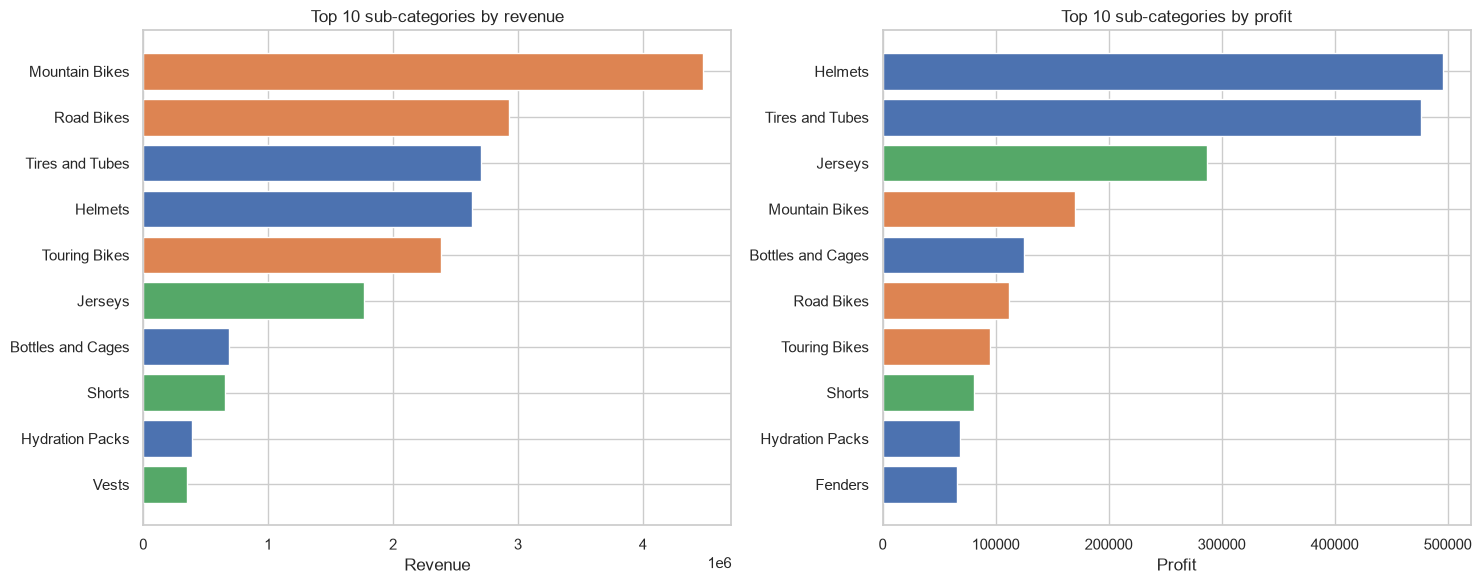

In [52]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, col, title in zip(ax, ["Revenue", "Profit"], ["Top 10 sub-categories by revenue", "Top 10 sub-categories by profit"]):
    t = subcat.sort_values(col, ascending=False).head(10).iloc[::-1]
    a.barh(t["Sub Category"], t[col], color=t["Product Category"].map(palette))
    a.set_title(title)
    a.set_xlabel(col)
plt.tight_layout()
plt.show()

### Observations: Best-Selling Products

*The dataset has no product-name column, so **Sub Category** is used as the product level. Figures cover the 12 complete months (July 2015 to June 2016): 65,176 units sold across 17 sub-categories.*

| Rank | Sub-category | Category | Units | Share of units |
|---|---|---|---|---|
| 1 | Tires and Tubes | Accessories | 20,926 | 32.1% |
| 2 | Bottles and Cages | Accessories | 10,262 | 15.7% |
| 3 | Helmets | Accessories | 8,063 | 12.4% |
| 4 | Mountain Bikes | Bikes | 4,803 | 7.4% |
| 5 | Road Bikes | Bikes | 4,775 | 7.3% |
| 6 | Jerseys | Clothing | 3,875 | 5.9% |
| 7 | Caps | Clothing | 2,886 | 4.4% |
| 8 | Touring Bikes | Bikes | 2,673 | 4.1% |
| 9 | Fenders | Accessories | 1,385 | 2.1% |
| 10 | Shorts | Clothing | 1,067 | 1.6% |

- **Sales are highly concentrated.** The top 10 account for **93.2%** of all units and the top 3 (Tires and Tubes, Bottles and Cages, Helmets) for **60.2%**. Tires and Tubes alone sell about 1 in 3 units, twice as many as the runner-up.
- **The top 10 mix all three categories:** four Accessories, three Bikes and three Clothing items. The three biggest sellers are all Accessories.
- **The two best-selling bike types are almost tied** (Mountain Bikes 4,803 and Road Bikes 4,775 units).
- Customers buy an average of 2 units per transaction, so ranking by transactions gives the same order as ranking by units.
- The seven smallest sub-categories (Cleaners, Gloves, Hydration Packs, Socks, Vests, Bike Stands and Bike Racks) share only 6.8% of units.

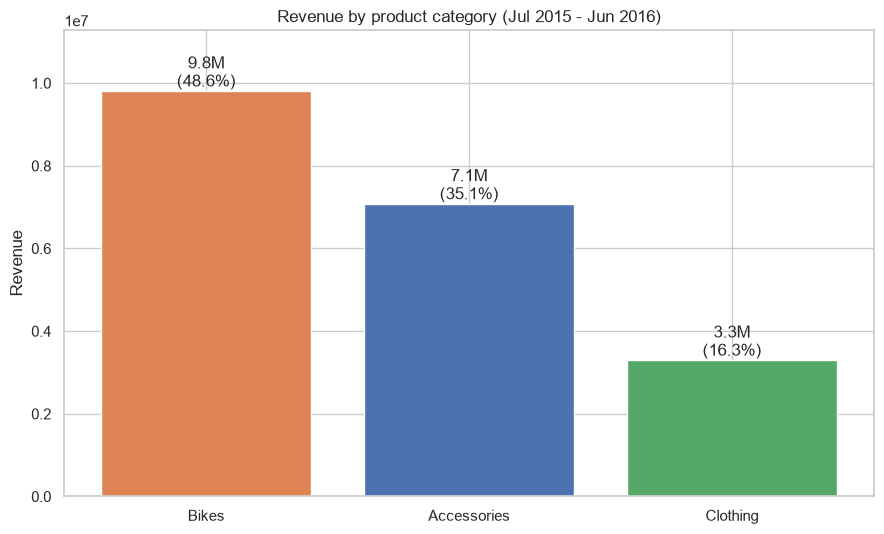

,Units,Transactions,Revenue,Profit,Margin %,Revenue share %
Product Category,,,,,,
Bikes,12251,6065,9803063.0,377063.0,3.8,48.6
Accessories,42933,21481,7075346.0,1301032.0,18.4,35.1
Clothing,9992,5005,3291263.0,515817.0,15.7,16.3


In [53]:
cat = data_full.groupby("Product Category").agg(
    Units=("Quantity", "sum"),
    Transactions=("Revenue", "size"),
    Revenue=("Revenue", "sum"),
    Profit=("Profit", "sum")
).sort_values("Revenue", ascending=False)
cat["Margin %"] = (cat["Profit"] / cat["Revenue"] * 100).round(1)
cat["Revenue share %"] = (cat["Revenue"] / cat["Revenue"].sum() * 100).round(1)

plt.figure(figsize=(9, 5.5))
bars = plt.bar(cat.index, cat["Revenue"], color=[palette[c] for c in cat.index])
for b, v, s in zip(bars, cat["Revenue"], cat["Revenue share %"]):
    plt.text(b.get_x() + b.get_width() / 2, v, f"{v / 1e6:.1f}M\n({s}%)", ha="center", va="bottom")
plt.title("Revenue by product category (Jul 2015 - Jun 2016)")
plt.ylabel("Revenue")
plt.ylim(0, cat["Revenue"].max() * 1.15)
plt.tight_layout()
plt.show()
cat.round(1)

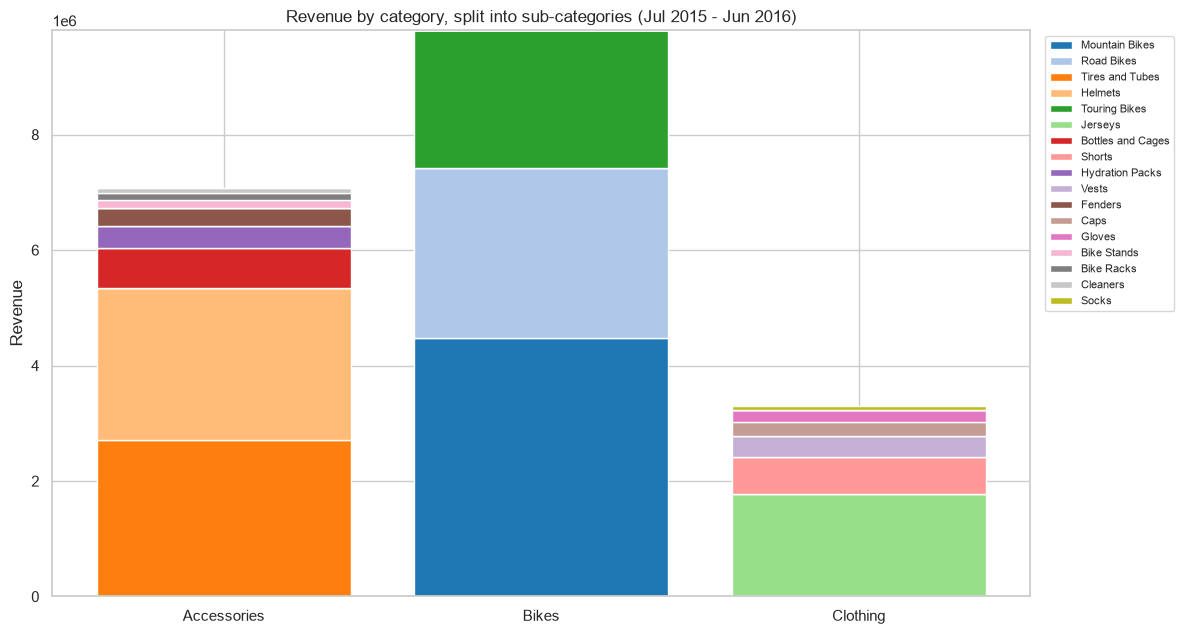

In [57]:
pv = data_full.pivot_table(index="Product Category", columns="Sub Category", values="Revenue", aggfunc="sum").fillna(0)
order = subcat.sort_values("Revenue", ascending=False)["Sub Category"]
colors = plt.cm.tab20(np.arange(len(order)))

fig, ax = plt.subplots(figsize=(12, 6.5))
bottom = np.zeros(len(pv))
for sc, col in zip(order, colors):
    ax.bar(pv.index, pv[sc].values, bottom=bottom, label=sc, color=col)
    bottom += pv[sc].values
ax.set_title("Revenue by category, split into sub-categories (Jul 2015 - Jun 2016)")
ax.set_ylabel("Revenue")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

### Observations: Revenue by Product Category

| Category | Units | Revenue | Revenue share | Profit | Margin |
|---|---|---|---|---|---|
| Bikes | 12,251 | 9,803,063 | **48.6%** | 377,063 | 3.8% |
| Accessories | 42,933 | 7,075,346 | 35.1% | 1,301,032 | 18.4% |
| Clothing | 9,992 | 3,291,263 | 16.3% | 515,817 | 15.7% |
| **Total** | 65,176 | 20,169,672 | 100% | 2,193,912 | 10.9% |

- **Bikes are the biggest revenue category** (48.6%) even though they are only 18.8% of units. Accessories sell **3.5 times as many units** as Bikes but bring in about **28% less revenue** (7.08M vs 9.80M).
- **Within Bikes:** Mountain Bikes are the largest single sub-category by revenue (4,485,028, 22.2% of total), followed by Road Bikes (2,930,125, 14.5%) and Touring Bikes (2,387,910, 11.8%).
- **Within Accessories:** revenue is led by Tires and Tubes (2,706,209, 13.4% of total) and Helmets (2,635,572, 13.1%). Bottles and Cages sell 10,262 units but earn only 690,393 (3.4%), because each unit is cheap (average price 82).
- **Within Clothing:** Jerseys make up 53.7% of category revenue (1,767,628, 8.8% of total), followed by Shorts (653,447, 3.2%).
- The five largest sub-categories by revenue (Mountain Bikes, Road Bikes, Tires and Tubes, Helmets, Touring Bikes) bring in 75.0% of total revenue.
- **Revenue and profit rank the categories differently.** Bikes are first on revenue but last on profit margin (3.8% against 18.4% for Accessories and 15.7% for Clothing); see the next section.

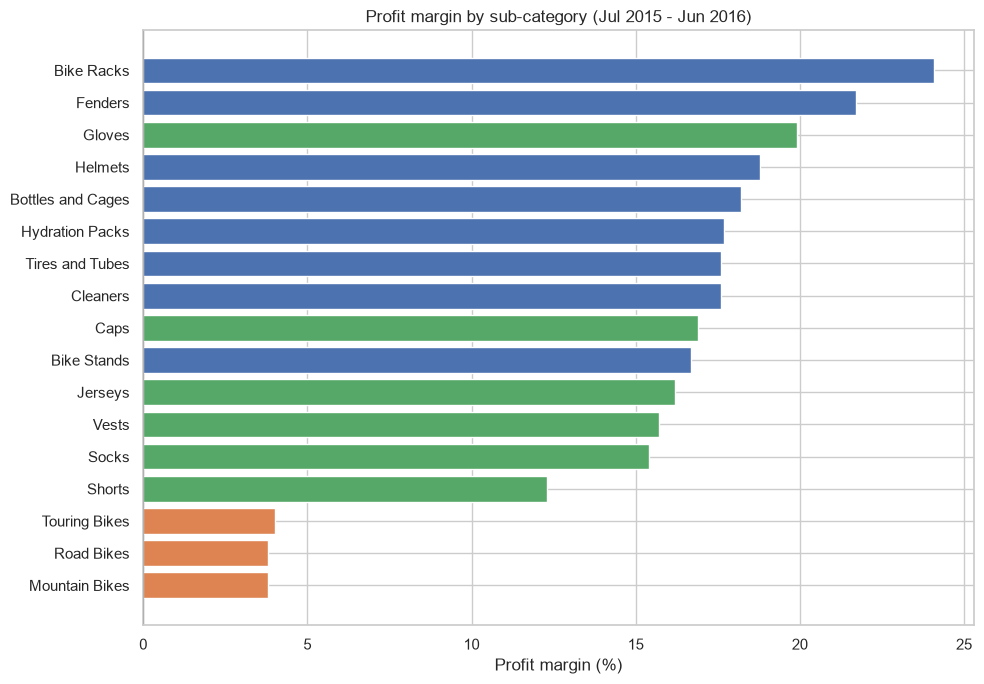

In [55]:
m = subcat.sort_values("Margin %")
plt.figure(figsize=(10, 7))
plt.barh(m["Sub Category"], m["Margin %"], color=m["Product Category"].map(palette))
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Profit margin by sub-category (Jul 2015 - Jun 2016)")
plt.xlabel("Profit margin (%)")
plt.tight_layout()
plt.show()

In [56]:
loss = data_full.assign(Loss=data_full["Profit"] < 0).groupby("Sub Category").agg(
    Transactions=("Loss", "size"),
    Loss_making=("Loss", "sum"),
    Loss_share_pct=("Loss", lambda s: s.mean() * 100)
)
loss["Share of all losses %"] = (loss["Loss_making"] / loss["Loss_making"].sum() * 100).round(1)
loss.sort_values("Loss_making", ascending=False).round(1)

,Transactions,Loss_making,Loss_share_pct,Share of all losses %
Sub Category,,,,
Road Bikes,2342,1039,44.4,25.0
Mountain Bikes,2389,1033,43.2,24.8
Touring Bikes,1334,551,41.3,13.2
Tires and Tubes,10477,508,4.8,12.2
Bottles and Cages,5142,225,4.4,5.4
Jerseys,1924,220,11.4,5.3
Helmets,4017,216,5.4,5.2
Caps,1456,145,10.0,3.5
Shorts,536,69,12.9,1.7


In [58]:
bike_loss = data[data["Product Category"] == "Bikes"].assign(Loss=lambda d: d["Profit"] < 0).groupby("Quarter").agg(
    Transactions=("Loss", "size"),
    Loss_making=("Loss", "sum"),
    Loss_share_pct=("Loss", lambda s: s.mean() * 100)
)
bike_loss.round(1)

,Transactions,Loss_making,Loss_share_pct
Quarter,,,
2015Q1,441,286,64.9
2015Q2,587,377,64.2
2015Q3,1084,724,66.8
2015Q4,1609,1128,70.1
2016Q1,1463,343,23.4
2016Q2,1909,428,22.4


In [59]:
h1_16 = data[(data["Date"] >= "2016-01-01") & (data["Date"] <= "2016-06-30")]
loss16 = h1_16.assign(Loss=h1_16["Profit"] < 0).groupby(["Product Category", "Sub Category"]).agg(
    Transactions=("Loss", "size"),
    Loss_making=("Loss", "sum"),
    Loss_share_pct=("Loss", lambda s: s.mean() * 100),
    Margin_pct=("Profit", lambda s: 0)
)
m16 = h1_16.groupby(["Product Category", "Sub Category"])[["Profit", "Revenue"]].sum()
loss16["Margin_pct"] = (m16["Profit"] / m16["Revenue"] * 100)
loss16.sort_values("Loss_share_pct", ascending=False).round(1)

Transactions  Loss_making  Loss_share_pct  \
Product Category Sub Category                                                   
Bikes            Touring Bikes               754          174            23.1   
                 Road Bikes                 1253          286            22.8   
                 Mountain Bikes             1365          311            22.8   
Clothing         Jerseys                    1033           46             4.5   
                 Vests                       157            6             3.8   
Accessories      Bike Stands                  65            2             3.1   
Clothing         Socks                       197            6             3.0   
Accessories      Helmets                    2236           68             3.0   
Clothing         Shorts                      268            8             3.0   
                 Gloves                      443           13             2.9   
Accessories      Tires and Tubes            5699          159             2.8   
Clothing         Caps                        826           21             2.5   
Accessories      Bottles and Cages          2966           69             2.3   
                 Fenders                     705           16             2.3   
                 Bike Racks                   95            2             2.1   
                 Cleaners                    289            6             2.1   
                 Hydration Packs             209            4             1.9   

                                    Margin_pct  
Product Category Sub Category                   
Bikes            Touring Bikes             8.5  
                 Road Bikes                9.5  
                 Mountain Bikes            8.9  
Clothing         Jerseys                  21.2  
                 Vests                    21.0  
Accessories      Bike Stands              22.0  
Clothing         Socks                    20.7  
Accessories      Helmets                  23.2  
Clothing         Shorts                   17.6  
                 Gloves                   19.9  
Accessories      Tires and Tubes          22.1  
Clothing         Caps                     21.8  
Accessories      Bottles and Cages        22.2  
                 Fenders                  21.7  
                 Bike Racks               24.1  
                 Cleaners                 22.2  
                 Hydration Packs          22.0

**Loss-making sales (12 complete months: 4,161 of 32,551 transactions, 12.8%)**

| Sub-category | Transactions | Loss-making | Loss rate | Share of all losses |
|---|---|---|---|---|
| Road Bikes | 2,342 | 1,039 | 44.4% | 25.0% |
| Mountain Bikes | 2,389 | 1,033 | 43.2% | 24.8% |
| Touring Bikes | 1,334 | 551 | 41.3% | 13.2% |
| Tires and Tubes | 10,477 | 508 | 4.8% | 12.2% |
| Bottles and Cages | 5,142 | 225 | 4.4% | 5.4% |
| Jerseys | 1,924 | 220 | 11.4% | 5.3% |
| Helmets | 4,017 | 216 | 5.4% | 5.2% |

- Over the 12 months, **Bikes lose money on 43.2% of sales** (2,623 of 6,065 transactions) and account for **63.0% of all loss-making transactions** while making up only 18.6% of transactions. Outside Bikes, only 5.8% of sales lose money.
- **This 12-month picture is dominated by 2015.** Splitting by period shows a sharp change:

| Period | Bike transactions | Loss-making | Loss rate |
|---|---|---|---|
| 2015 Q3 | 1,084 | 724 | 66.8% |
| 2015 Q4 | 1,609 | 1,128 | 70.1% |
| 2016 Q1 | 1,463 | 343 | 23.4% |
| 2016 Q2 | 1,909 | 428 | 22.4% |

  In the second half of 2015, **68.8%** of bike sales lost money (1,852 of 2,693). In the first half of 2016 the rate fell to **22.9%** (771 of 3,372). The drop coincides with the price increases and margin jump described in the time series observations, so the 12-month figure of 43.2% averages two very different periods and should not be read as the current rate.

**The current picture (January to June 2016)**

| Group | Transactions | Loss-making | Loss rate | Margin |
|---|---|---|---|---|
| Touring Bikes | 754 | 174 | 23.1% | 8.5% |
| Road Bikes | 1,253 | 286 | 22.8% | 9.5% |
| Mountain Bikes | 1,365 | 311 | 22.8% | 8.9% |
| All 14 other sub-categories | 15,188 | 426 | 2.8% | 17.6% to 24.1% |

- **The loss problem is now confined to bikes.** All three bike types still lose money on about **23% of sales** with margins of only 8.5% to 9.5%, while every other sub-category has a loss rate between 1.9% and 4.5% and a margin of at least 17.6%.
- Bikes are 18.2% of transactions in this period but **64.4% of all loss-making sales** (771 of 1,197).
- The three bike types behave almost identically (loss rates within 0.3 points of each other), which points to a **category-wide pricing or discounting practice**, not a weakness of one model.
- **Clothing and Accessories recovered fully.** Clothing's loss rate, 10% to 13% across the 12 months, fell to between 2.5% and 4.5% in 2016, and Accessories sit between 1.9% and 3.1%. Their 12-month loss rates were also a 2015 effect.
- **Caution:** a "loss" here means revenue below recorded cost on a single transaction. The data does not say why (discounts, price changes, cost updates), so the cause cannot be confirmed from this dataset.

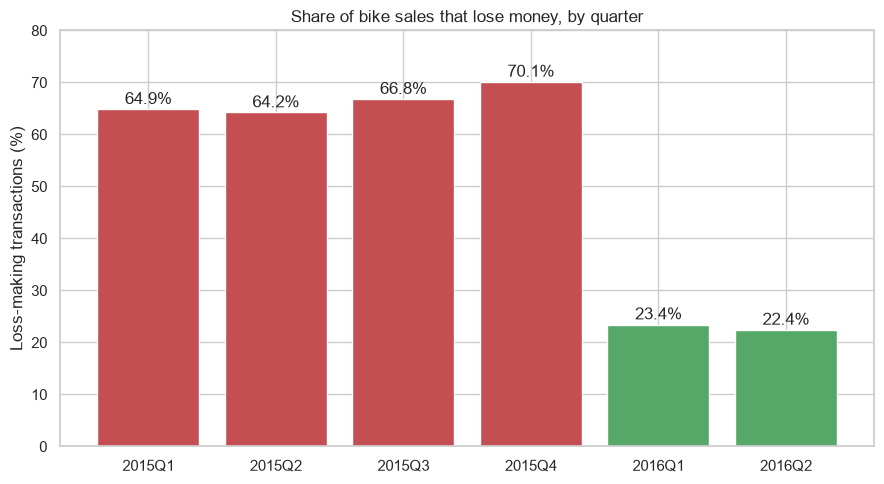

In [60]:
bl = bike_loss["Loss_share_pct"]
plt.figure(figsize=(9, 5))
colors = ["#c44e52" if "2015" in str(q) else "#55a868" for q in bl.index]
plt.bar(bl.index.astype(str), bl.values, color=colors)
for i, v in enumerate(bl.values):
    plt.text(i, v + 1, f"{v:.1f}%", ha="center")
plt.title("Share of bike sales that lose money, by quarter")
plt.ylabel("Loss-making transactions (%)")
plt.ylim(0, 80)
plt.tight_layout()
plt.show()

In [62]:
num = data_full[["Customer Age", "Quantity", "Unit Cost", "Unit Price", "Cost", "Revenue", "Profit", "Profit Margin %"]]
print(num.shape)
num.corr().round(2)

(32551, 8)


,Customer Age,Quantity,Unit Cost,Unit Price,Cost,Revenue,Profit,Profit Margin %
Customer Age,1.00,0.00,0.03,0.03,0.03,0.03,0.01,-0.00
Quantity,0.00,1.00,-0.31,-0.32,0.01,0.01,0.01,0.01
Unit Cost,0.03,-0.31,1.00,0.98,0.86,0.84,0.21,-0.28
Unit Price,0.03,-0.32,0.98,1.00,0.84,0.85,0.37,-0.16
Cost,0.03,0.01,0.86,0.84,1.00,0.98,0.25,-0.32
Revenue,0.03,0.01,0.84,0.85,0.98,1.00,0.44,-0.18
Profit,0.01,0.01,0.21,0.37,0.25,0.44,1.00,0.54
Profit Margin %,-0.00,0.01,-0.28,-0.16,-0.32,-0.18,0.54,1.00


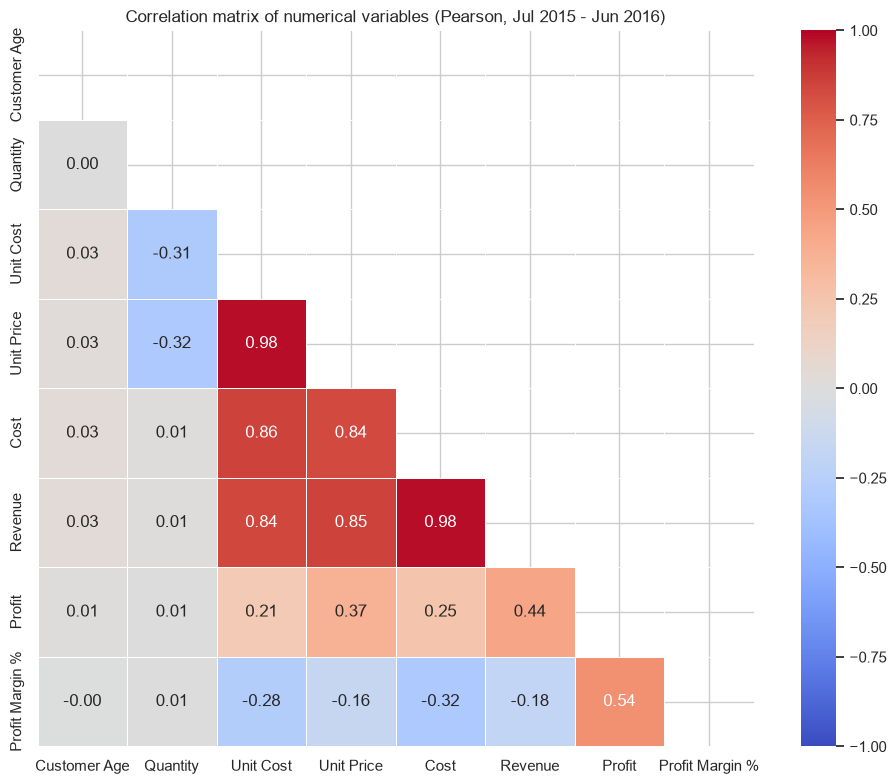

In [63]:
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(num.corr(), dtype=bool))
sns.heatmap(num.corr(), mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Correlation matrix of numerical variables (Pearson, Jul 2015 - Jun 2016)")
plt.tight_layout()
plt.show()

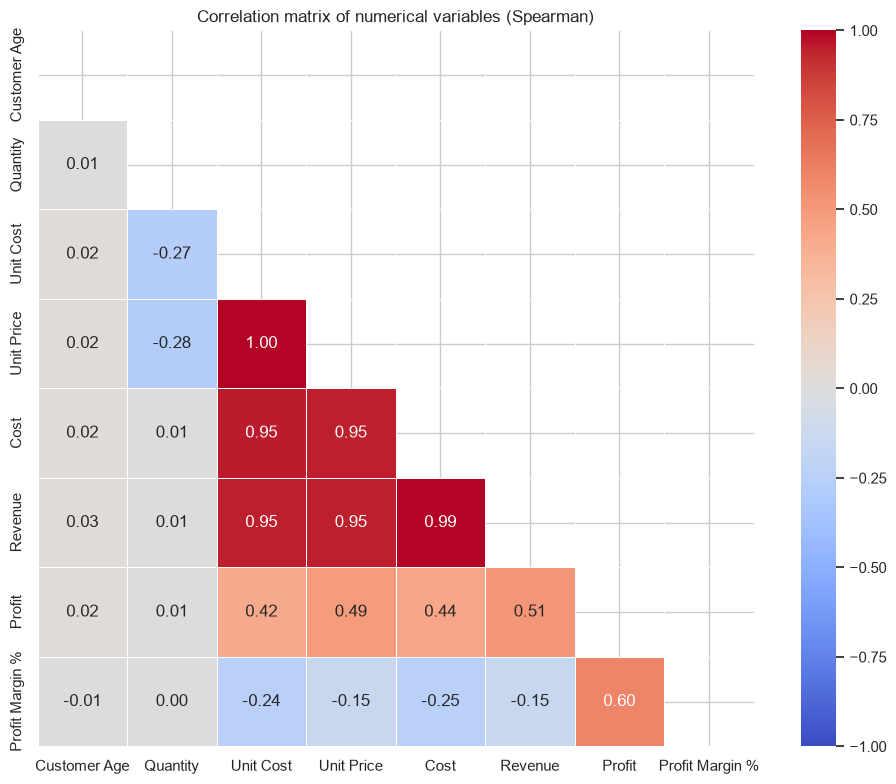

In [64]:
plt.figure(figsize=(10, 8))
sp = num.corr(method="spearman")
sns.heatmap(sp, mask=np.triu(np.ones_like(sp, dtype=bool)), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Correlation matrix of numerical variables (Spearman)")
plt.tight_layout()
plt.show()

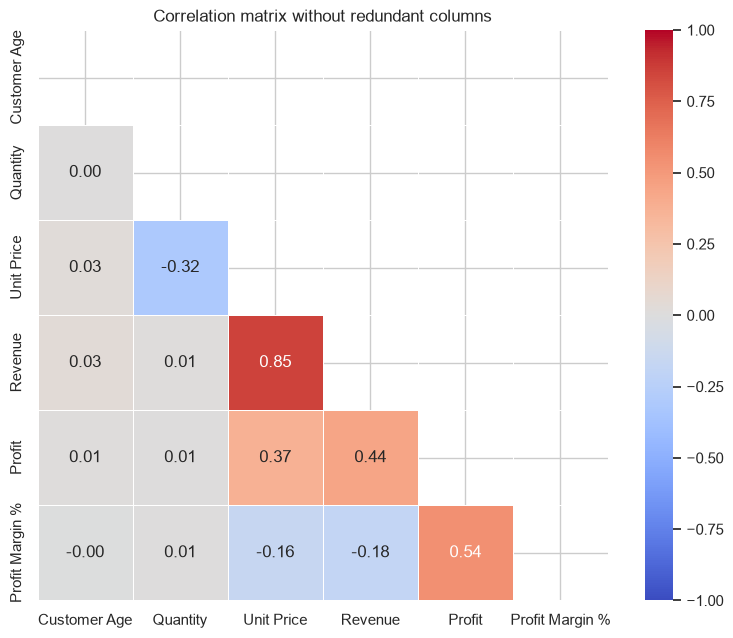

In [65]:
core = data_full[["Customer Age", "Quantity", "Unit Price", "Revenue", "Profit", "Profit Margin %"]]
plt.figure(figsize=(8, 6.5))
cc = core.corr()
sns.heatmap(cc, mask=np.triu(np.ones_like(cc, dtype=bool)), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Correlation matrix without redundant columns")
plt.tight_layout()
plt.show()

In [66]:
c = num.corr()
pairs = c.where(np.triu(np.ones(c.shape, dtype=bool), k=1)).stack().reset_index()
pairs.columns = ["Variable 1", "Variable 2", "Correlation"]
pairs["Abs"] = pairs["Correlation"].abs()
by_definition = {
    frozenset(["Unit Cost", "Unit Price"]),
    frozenset(["Cost", "Revenue"]),
    frozenset(["Revenue", "Profit"]),
    frozenset(["Cost", "Profit"]),
    frozenset(["Quantity", "Cost"]),
    frozenset(["Quantity", "Revenue"]),
    frozenset(["Unit Price", "Revenue"]),
    frozenset(["Unit Price", "Cost"]),
    frozenset(["Unit Cost", "Revenue"]),
    frozenset(["Unit Cost", "Cost"]),
}
pairs["Built in?"] = pairs.apply(lambda r: "yes" if frozenset([r["Variable 1"], r["Variable 2"]]) in by_definition else "", axis=1)
pairs.sort_values("Abs", ascending=False).drop(columns="Abs").round(2).head(15)

,Variable 1,Variable 2,Correlation,Built in?
19,Unit Cost,Unit Price,0.98,yes
37,Cost,Revenue,0.98,yes
20,Unit Cost,Cost,0.86,yes
29,Unit Price,Revenue,0.85,yes
21,Unit Cost,Revenue,0.84,yes
28,Unit Price,Cost,0.84,yes
55,Profit,Profit Margin %,0.54,
46,Revenue,Profit,0.44,yes
30,Unit Price,Profit,0.37,
11,Quantity,Unit Price,-0.32,


In [67]:
for cat in ["Accessories", "Bikes", "Clothing"]:
    s = data_full[data_full["Product Category"] == cat]
    print(cat, "| Age vs Revenue:", round(s["Customer Age"].corr(s["Revenue"]), 3),
          "| Age vs Profit:", round(s["Customer Age"].corr(s["Profit"]), 3),
          "| Age vs Quantity:", round(s["Customer Age"].corr(s["Quantity"]), 3))

Accessories | Age vs Revenue: 0.024 | Age vs Profit: 0.012 | Age vs Quantity: 0.007
Bikes | Age vs Revenue: 0.171 | Age vs Profit: -0.003 | Age vs Quantity: -0.021
Clothing | Age vs Revenue: 0.048 | Age vs Profit: 0.028 | Age vs Quantity: 0.015


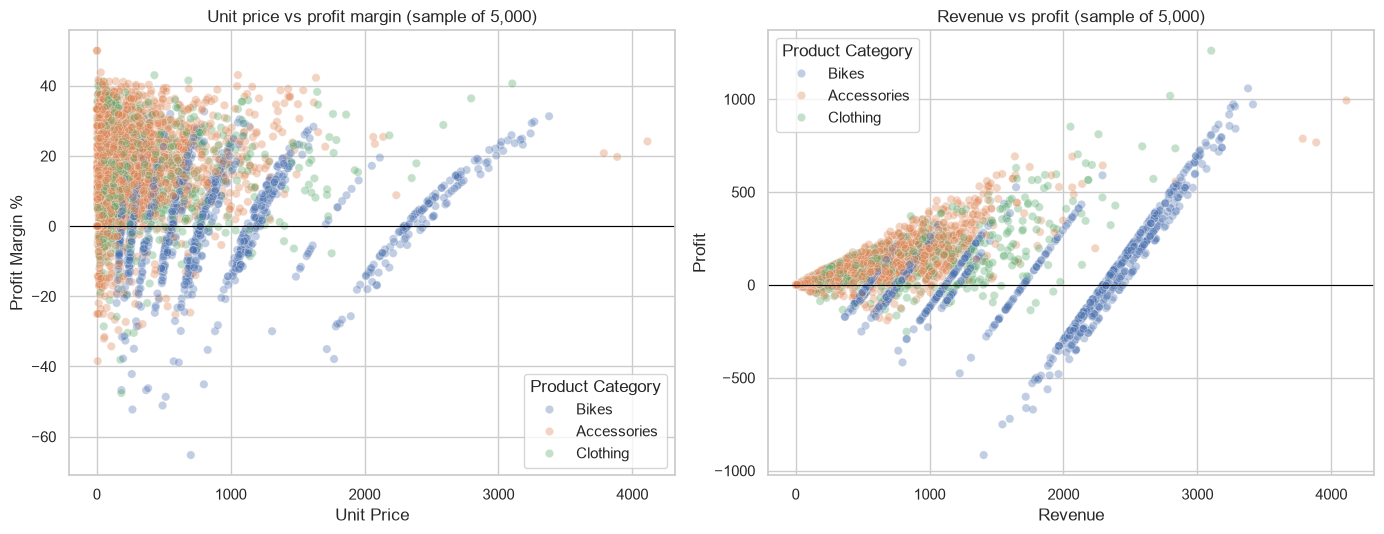

In [68]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(data=data_full.sample(5000, random_state=1), x="Unit Price", y="Profit Margin %", hue="Product Category", alpha=0.35, ax=ax[0])
ax[0].set_title("Unit price vs profit margin (sample of 5,000)")
ax[0].axhline(0, color="black", linewidth=0.8)

sns.scatterplot(data=data_full.sample(5000, random_state=1), x="Revenue", y="Profit", hue="Product Category", alpha=0.35, ax=ax[1])
ax[1].set_title("Revenue vs profit (sample of 5,000)")
ax[1].axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

In [69]:
b = data_full[data_full["Product Category"] == "Bikes"]
print(b[["Customer Age", "Quantity", "Unit Price", "Revenue", "Profit", "Profit Margin %"]].corr().round(2))

                 Customer Age  Quantity  Unit Price  Revenue  Profit  \
Customer Age             1.00     -0.02        0.13     0.17   -0.00   
Quantity                -0.02      1.00       -0.60     0.01    0.01   
Unit Price               0.13     -0.60        1.00     0.70    0.28   
Revenue                  0.17      0.01        0.70     1.00    0.41   
Profit                  -0.00      0.01        0.28     0.41    1.00   
Profit Margin %         -0.02      0.02        0.17     0.26    0.87   

                 Profit Margin %  
Customer Age               -0.02  
Quantity                    0.02  
Unit Price                  0.17  
Revenue                     0.26  
Profit                      0.87  
Profit Margin %             1.00  


### Observations: Correlation Analysis

*Computed on the 12 complete months (July 2015 to June 2016, 32,551 transactions). The money columns are linked by definition (Revenue = Quantity x Unit Price, Cost = Quantity x Unit Cost, Profit = Revenue - Cost, Profit Margin % = Profit / Revenue), so their strong correlations are arithmetic and not findings. Pearson and Spearman are both shown because the money columns are right-skewed.*

**Relationships built into the data**
- Unit Cost and Unit Price (0.98), Cost and Revenue (0.98), Unit Cost and Cost (0.86), Unit Price and Revenue (0.85), Unit Cost and Revenue (0.84) and Unit Price and Cost (0.84) are all high because of how the columns are built.
- Profit and Profit Margin % (0.54) are also partly linked by construction.
- A reduced heatmap without the redundant columns (cost-based columns removed) is shown for readability.

**Relationships that carry information**

| Pair | Pearson | Spearman | Reading |
|---|---|---|---|
| Revenue and Profit | 0.44 | 0.51 | Moderate: bigger orders give more profit, but far from proportionally |
| Unit Price and Profit | 0.37 | 0.49 | Pricier items earn somewhat more profit |
| Unit Price and Profit Margin % | -0.16 | -0.15 | Weakly negative overall (a category effect, see below) |
| Cost and Profit Margin % | -0.32 | -0.25 | Costlier orders have thinner margins |
| Quantity and Unit Price | -0.32 | -0.28 | Larger quantities are cheaper items |
| Quantity and Revenue | 0.01 | 0.01 | Buying more units does not mean spending more |
| Customer Age and Revenue | 0.03 | 0.03 | No linear relationship |
| Customer Age and Profit | 0.01 | 0.02 | No linear relationship |

- **Revenue is only a moderate guide to profit** (0.44). A large order does not guarantee a large profit: the scatter of revenue against profit shows that many of the biggest orders (bikes) earn little or even lose money.
- **Quantity does not drive revenue** (0.01), because larger quantities go with cheaper items (-0.32 with unit price overall, and -0.60 within bikes). Orders hold only 1 to 3 units, and the price differences between items (from under 1 to over 5,000) dwarf the quantity differences.
- **Pearson and Spearman agree on the signs.** Spearman is higher for the profit relationships (for example Unit Price and Profit 0.49 against 0.37), meaning the ranking relationship is stronger than the straight-line one, because a few large-loss bike sales pull the Pearson value down.

**Age: no linear relationship overall, but not "no effect"**
- Customer age has a correlation of only 0.03 with revenue and 0.01 with profit.
- This does **not** mean age is irrelevant. The age-group analysis showed an inverted-U pattern in average spend (482 for ages 17-24, 641 for 25-34, 674 for 35-44, 633 for 45-54, 567 for 55-64 and 460 for 65+), which a straight-line correlation cannot capture.
- **Within each category** the age correlation with revenue is: Bikes 0.17, Clothing 0.05 and Accessories ___ (fill from your output). Only bikes show a noticeable link, and it is weak: older bike buyers spend somewhat more per bike (age and unit price 0.13) but this does not translate into profit (age and bike profit -0.00).

**Price and margin: the sign depends on the level you look at**
- Across all products, unit price and margin are weakly **negative** (-0.16): expensive bikes carry thin margins, cheap accessories carry high ones.
- Within bikes, the relationship turns weakly **positive** (+0.17). Inside this category, higher-priced sales have somewhat better margins, and the scatter shows each bike model forming a diagonal band in which margin rises with the selling price and falls below zero at low prices.
- So the overall negative sign reflects the mix of categories and is **not a rule that higher prices lower margins**.
- Within bikes, profit is driven mostly by margin (0.87) and only weakly by revenue (0.41) or unit price (0.28). The size of a bike sale tells little about its profit.

**Takeaway:** customer age and order quantity have almost no straight-line relationship with profit. What determines profit is **which product is sold and at what price relative to its cost**, which is consistent with the finding that Bikes bring in 48.6% of revenue but only 17.2% of profit. Correlation describes this dataset and does not show that changing one variable would change another.

In [70]:
b16 = data[(data["Product Category"] == "Bikes") & (data["Date"] >= "2016-01-01") & (data["Date"] <= "2016-06-30")]
lost = b16.loc[b16["Profit"] < 0, "Profit"].sum()
earned = b16.loc[b16["Profit"] > 0, "Profit"].sum()
print("Profit from profitable bike sales:", round(earned))
print("Losses on loss-making bike sales:", round(lost))
print("Net bike profit, Jan-Jun 2016:", round(earned + lost))
print("Losses as % of profit earned:", round(abs(lost) / earned * 100, 1))

Profit from profitable bike sales: 601026
Losses on loss-making bike sales: -88091
Net bike profit, Jan-Jun 2016: 512935
Losses as % of profit earned: 14.7


## Conclusion and Business Recommendations

### Summary of key findings

| Area | Finding |
|---|---|
| **Data** | 34,866 transactions from January 2015 to July 2016. Before July 2015 only Bikes are recorded, and July 2016 has no bike sales, so growth and category comparisons use July 2015 to June 2016 (32,551 transactions, 20.2M revenue, 2.19M profit, 10.9% margin). |
| **Growth** | Like for like, **bike revenue grew +239.9%** between H1 2015 and H1 2016, almost entirely through more orders (+228.0%), not bigger orders (+3.6% revenue per transaction). The headline +607% is inflated by Accessories and Clothing entering the data in July 2015. |
| **Customers** | Transactions are split almost evenly by gender (51.1% male, 48.9% female). The **25-44 age range makes 62.1% of transactions and 65.7% of revenue**. Gender has no meaningful effect on spending, margin or category choice. |
| **Products** | Sales are concentrated: the top 3 sub-categories (Tires and Tubes, Bottles and Cages, Helmets) are 60.2% of units. Bikes are 18.8% of units but 48.6% of revenue. |
| **Profit** | Revenue and profit tell different stories. Bikes bring in **48.6% of revenue but only 17.2% of profit** (3.8% margin), while Accessories bring in 35.1% of revenue and **59.3% of profit** (18.4% margin). |
| **Losses** | Bike sales lost money 68.8% of the time in H2 2015 and 22.9% in H1 2016. In H1 2016 bikes are 18.2% of transactions but **64.4% of loss-making sales**, while all other sub-categories lose money on only 2.8% of sales. |
| **Correlations** | Age and quantity have almost no straight-line relationship with profit. What determines profit is which product is sold and its price relative to cost. |

### Recommendations

**1. Put a price floor under bikes (highest priority).**
- *Evidence:* Bikes are the largest revenue category (48.6%) but have the thinnest margin (3.8% over 12 months, about 9% in 2016 against about 22% for Accessories and about 20% for Clothing). Even after the 2016 price increases, about **23% of bike sales still lose money** (Touring 23.1%, Road 22.8%, Mountain 22.8%), and the three types behave almost identically, which points to a category-wide pricing or discounting practice.
- *Action:* set a minimum selling price (or maximum discount) per bike model so that no sale falls below cost, and require approval for exceptions.
- *Why it matters:* bike revenue was 5.72M in H1 2016, so each extra point of bike margin is worth about 57,000 in profit (illustrative arithmetic), roughly 3.1% of that period's total profit (1.87M).
- *Track:* share of bike sales below cost (target: close to the 2.8% seen outside bikes) and bike margin by quarter.

**2. Give priority to the products that generate the profit: Helmets, Tires and Tubes, and Jerseys.**
- *Evidence:* these three sub-categories produce **57.4% of all profit from 35.2% of revenue**. Helmets are the single most profitable product (495,777, margin 18.8%), earning about three times the profit of Mountain Bikes (170,079) from 41% less revenue. Tires and Tubes are the volume leader (32.1% of units, 17.6% margin).
- *Action:* protect stock levels and feature these lines in promotions. Review the weakest lines (Caps rank 7th on units but 13th on profit; Socks and Cleaners are in the bottom three on profit) before spending marketing money on them.
- *Track:* profit per sub-category, not only units or revenue, as the main ranking in reports.

**3. Focus acquisition on customers aged 25-44 and grow the under-25 segment with entry-level offers.**
- *Evidence:* the 25-44 range generates 65.7% of revenue and has the highest spending per transaction (673.9 for ages 35-44, against 619.6 overall), because they buy the most bikes (22.4% of transactions for ages 25-34 and 20.4% for 35-44). Customers under 25 spend about 22% less per order (482.1) and buy bikes in only 12.2% of their transactions.
- *Action:* aim bike campaigns at ages 25-44. For ages 17-24, lead with accessories and clothing (which make up 87.9% of their transactions) as a route into the brand. **Do not segment by gender**: spending (617.8 vs 621.5 per transaction), margin (10.9% vs 10.8%) and category mix are practically identical.
- *Track:* revenue and bike share by age group.

**4. Fix the data before the next analysis.**
- *Evidence:* the data has no order or customer ID, no product names and no discount field. It lacks bike sales for July 2016, and a loss-making sale cannot be explained.
- *Action:* record order ID, customer ID, product name or SKU, and discount applied, and investigate why bike sales stop on 30 June 2016.
- *Why it matters:* without order IDs the business cannot tell whether accessories are bought together with bikes (a common reason for loss-leader bike pricing), cannot measure repeat purchases, and cannot tell whether bike losses come from discounting or from cost changes.

**Worth watching (not a firm recommendation):** revenue peaked in December 2015 (2,116,097, +47.1% over November; bikes +61.3%). With only one December in the data this cannot be confirmed as seasonality, so check whether it repeats in December 2016 before planning stock around it.

### Limitations
- **Transactions, not customers.** There is no customer or order ID, so repeat buying, basket contents and customer value cannot be analysed.
- **Sub-category stands in for "product".** The dataset has no product names, so the "top 10 best-selling products" are the 10 largest of 17 sub-categories.
- **Uneven coverage.** January to June 2015 contains Bikes only, and July 2016 has no bike sales, so some comparisons were restricted to July 2015 to June 2016 or to bikes alone.
- **Averages hide detail.** The price-increase explanation for the margin jump rests on average unit prices per sub-category and is consistent with the data, but a change in the model mix could contribute.
- **Cause of losses unknown.** A loss means revenue below recorded cost on a transaction. The data does not say whether discounting, price changes or cost updates caused it.
- **Correlation is not causation.** Correlations describe this dataset and do not show that changing one variable would change another. Age correlations in particular are weak and hide a non-linear pattern.
- **Currency and period.** The currency is not stated, and the data covers only 19 months, so seasonal patterns cannot be confirmed.

In [72]:
%%writefile README.md
# Task 1 · EDA on Retail Sales Data

**Track:** Data Analytics · **Level:** 1 · **Internship:** OIBSIP

## Objective
Perform an exploratory data analysis on a retail sales dataset to uncover patterns, customer behaviour trends and actionable business insights.

## Tech Stack
Python, pandas, numpy, matplotlib, seaborn, Jupyter Notebook

## Dataset
"Sales Data For Economic Data Analysis" (Kaggle): 34,867 rows, 16 columns of individual sales transactions with date, customer age and gender, country and state, product category and sub-category, quantity, unit cost, unit price, cost and revenue. After cleaning, 34,866 transactions remain, covering **1 January 2015 to 31 July 2016**.

The data files are not included in this repository. Download the dataset from Kaggle (search the title above) and place the CSV in the `data/` folder.

## Project Structure
```
DataAnalytics-L1-EDARetailSales/
├── Task1_EDA_Retail_Sales.ipynb
├── README.md
├── requirements.txt
├── data/            (place the CSV here)
└── screenshots/     (charts from the analysis)
```

## How to Run
```bash
pip install -r requirements.txt
jupyter notebook Task1_EDA_Retail_Sales.ipynb
```
Then run all cells from top to bottom (Kernel → Restart & Run All). The notebook expects the file `data/salesforcourse-4fe2kehu.csv`; change the file name in the load cell if yours differs.

## What the Notebook Covers
- [x] Load the dataset and inspect shape, column types and null values
- [x] Descriptive statistics: mean, median, mode and standard deviation of all numerical columns
- [x] Time series analysis: monthly and quarterly sales trends (line charts)
- [x] Customer demographics: age groups and gender breakdown
- [x] Product analysis: top 10 best-selling products and revenue by product category
- [x] Correlation heatmap of the numerical variables
- [x] Additional visualisations: revenue vs profit share by category, and the bike loss rate by quarter
- [x] Written observations after each chart
- [x] Conclusion with specific, actionable business recommendations

## Data Cleaning Summary
- Removed 1 row that held only a revenue value and looked like a summary row added to the file
- Dropped `index` (row counter) and `Column1` (93% empty, a copy of `Revenue` where filled)
- Converted `Date` to datetime, and `Year`, `Customer Age` and `Quantity` to integers
- Found only 1 exact duplicate row and kept it, because there is no order ID
- Verified that `Revenue = Quantity x Unit Price` and `Cost = Quantity x Unit Cost` for every row, then added `Profit` and `Profit Margin %`

## Data Issues That Shaped the Analysis
- **Coverage changes over time.** January to June 2015 contains Bikes only, and Accessories and Clothing appear from July 2015. Bike sales are missing for all of July 2016. Category and product comparisons therefore use **July 2015 to June 2016** (32,551 transactions), and the July 2016 drop (-79%) is a data gap, not a sales collapse.
- **There are no product names.** Sub-category (17 values) is used as the product level.
- **There is no customer or order ID.** Results describe transactions, not unique customers.

## Key Findings
- **Growth:** like for like, bike revenue grew **+239.9%** from H1 2015 to H1 2016, almost entirely through more orders (+228.0%). The headline +607% is inflated by new categories entering the data.
- **Customers:** the 25-44 age range makes 62.1% of transactions and 65.7% of revenue. Gender is split almost evenly (51.1% male, 48.9% female) and makes no meaningful difference to spending, margin or category choice.
- **Products:** the top 3 sub-categories (Tires and Tubes, Bottles and Cages, Helmets) account for 60.2% of units sold.
- **Revenue is not profit.** Bikes bring in 48.6% of revenue but only 17.2% of profit (3.8% margin), while Accessories bring in 35.1% of revenue and 59.3% of profit (18.4% margin). Helmets are the most profitable product.
- **Margins jumped at the start of 2016** in every category (10 to 13 points) while the category mix barely changed. Average unit prices rose 6% to 17% while costs stayed flat, consistent with a price increase.
- **Losses are now confined to bikes.** 68.8% of bike sales lost money in H2 2015 and 22.9% in H1 2016, while all other sub-categories lose money on only 2.8% of sales.
- **Correlations:** age and quantity have almost no straight-line relationship with profit. Profit depends on which product is sold and its price relative to cost.

## Business Recommendations
1. **Put a price floor under bikes.** About 23% of bike sales still lose money, and bikes are the biggest revenue category with the thinnest margin. Set a minimum price or maximum discount per model.
2. **Prioritise the profit drivers: Helmets, Tires and Tubes, and Jerseys.** Together they produce 57.4% of profit from 35.2% of revenue. Rank products by profit, not units.
3. **Focus acquisition on ages 25-44** with bike campaigns, and use accessories and clothing as an entry route for under-25s. Do not segment by gender.
4. **Fix the data collection.** Record order ID, customer ID, product name and discount, and investigate why bike sales stop on 30 June 2016.

## Limitations
- No customer or order ID, so repeat purchases and baskets cannot be analysed
- Sub-category stands in for product; no product names are available
- Uneven category coverage over time and only 19 months of data, so seasonality cannot be confirmed
- The cause of loss-making sales (discounts, price changes or cost updates) is not in the data
- Correlations describe this dataset and do not prove cause and effect
- The currency is not stated

## Screenshots

### Monthly revenue trend
![Monthly revenue](screenshots/monthly_revenue_trend.png)

### Quarterly revenue trend
![Quarterly revenue](screenshots/quarterly_revenue_trend.png)

### Year-over-year comparison (January to June)
![Year over year](screenshots/yoy_comparison.png)

### Customer age distribution
![Age distribution](screenshots/age_distribution.png)

### Gender breakdown
![Gender breakdown](screenshots/gender_breakdown.png)

### Average revenue by age group and gender
![Average revenue by age and gender](screenshots/avg_revenue_age_gender.png)

### Top 10 best-selling products (sub-categories)
![Top 10 products](screenshots/top10_products_units.png)

### Revenue by product category
![Revenue by category](screenshots/revenue_by_category.png)

### Profit margin by sub-category
![Margin by sub-category](screenshots/margin_by_subcategory.png)

### Share of transactions, revenue and profit by category
![Category share comparison](screenshots/category_share_comparison.png)

### Share of bike sales that lose money, by quarter
![Bike loss rate](screenshots/bike_loss_rate_by_quarter.png)

### Correlation heatmap (all numerical variables)
![Correlation heatmap](screenshots/correlation_heatmap_full.png)

### Correlation heatmap (redundant columns removed)
![Reduced correlation heatmap](screenshots/correlation_heatmap_reduced.png)

### Unit price vs profit margin
![Price vs margin](screenshots/price_vs_margin_scatter.png)

Writing README.md


In [73]:
%%writefile requirements.txt
pandas
numpy
matplotlib
seaborn
jupyter

Writing requirements.txt


In [74]:
import os
print(os.getcwd())
print(os.listdir("."))

C:\Users\N6N0C\OIBSIP\DataAnalytics-L1-EDARetailSales
['.ipynb_checkpoints', 'anaconda_projects', 'data', 'README.md', 'requirements.txt', 'screenshots', 'Task1_EDA_Retail_Sales.ipynb']
